In [4]:
import pandas as pd
df = pd.read_csv('../data/telemetry.csv')
df.head()

,timestep,temperature,voltage,current,battery_level,orientation_x,orientation_y,orientation_z,anomaly,anomaly_type
0,0,5.243774,27.502540,2.365035,49.188370,0.131649,1.185080,0.000339,0,none
1,1,4.230844,28.279928,2.307923,47.639446,0.133663,1.978173,0.000107,0,none
2,2,5.726023,28.007723,2.543190,50.490086,0.091615,1.859249,0.000012,0,none
3,3,5.940942,27.857725,2.512949,46.777100,0.346649,1.334236,-0.000091,0,none
4,4,3.690488,27.975018,2.152913,45.862357,-0.066227,1.820225,-0.000491,0,none


In [5]:
df[df['anomaly']==1]['timestep'].head(20).tolist()
df['anomaly'].value_counts()

anomaly
0    19418
1      582
Name: count, dtype: int64

In [8]:
df[df['anomaly']==1]['timestep'].head(20).tolist()

[1239,
 1240,
 1241,
 1242,
 1243,
 1244,
 1245,
 1246,
 1247,
 1248,
 1249,
 1250,
 1251,
 1252,
 1253,
 1254,
 1255,
 1256,
 1257,
 1258]

In [9]:
feature_cols = ['temperature', 'voltage', 'current', 'battery_level',
                'orientation_x', 'orientation_y', 'orientation_z']
feature_cols = [col for col in df.columns if col not in ['timestep', 'anomaly', 'anomaly_type']]

In [10]:
X = df[feature_cols]
y = df['anomaly']

In [103]:

y.head()

0    0
1    0
2    0
3    0
4    0
Name: anomaly, dtype: int64

In [12]:
X.head()

,temperature,voltage,current,battery_level,orientation_x,orientation_y,orientation_z
0,5.243774,27.502540,2.365035,49.188370,0.131649,1.185080,0.000339
1,4.230844,28.279928,2.307923,47.639446,0.133663,1.978173,0.000107
2,5.726023,28.007723,2.543190,50.490086,0.091615,1.859249,0.000012
3,5.940942,27.857725,2.512949,46.777100,0.346649,1.334236,-0.000091
4,3.690488,27.975018,2.152913,45.862357,-0.066227,1.820225,-0.000491


In [13]:
split_point = 16000
X_train_raw = X.iloc[:split_point]
y_train_raw = y.iloc[:split_point]
X_test = X.iloc[split_point:]
y_test = y.iloc[split_point:]
X_train = X_train_raw[y_train_raw == 0]
print(f"Train(normal only):{X_train.shape}")
print(f"Test (all, for evaluation): {X_test.shape}")
print(f"Test anomaly rate: {y_test.mean()*100:.2f}%")

Train(normal only):(15555, 7)
Test (all, for evaluation): (4000, 7)
Test anomaly rate: 3.43%


In [17]:
def plot_channel(column_name):
    plt.figure(figsize=(15, 4))
    plt.plot(df['timestep'], df[column_name], label=column_name, linewidth=0.8, color='gray', alpha=0.6)
    
    colors = {'spike': 'red', 'drift': 'orange', 'freeze': 'purple'}
    for anomaly_type, color in colors.items():
        subset = df[df['anomaly_type'] == anomaly_type]
        plt.scatter(subset['timestep'], subset[column_name], color=color, s=15, label=anomaly_type, zorder=5)
    
    plt.xlabel('timestep')
    plt.ylabel(column_name)
    plt.title(f'{column_name} over time, colored by anomaly type')
    plt.legend()
    plt.show()

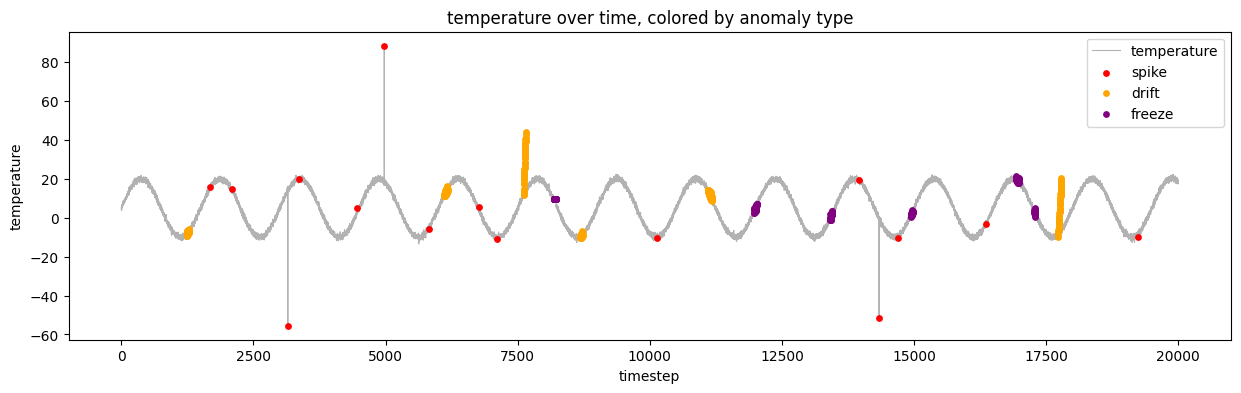

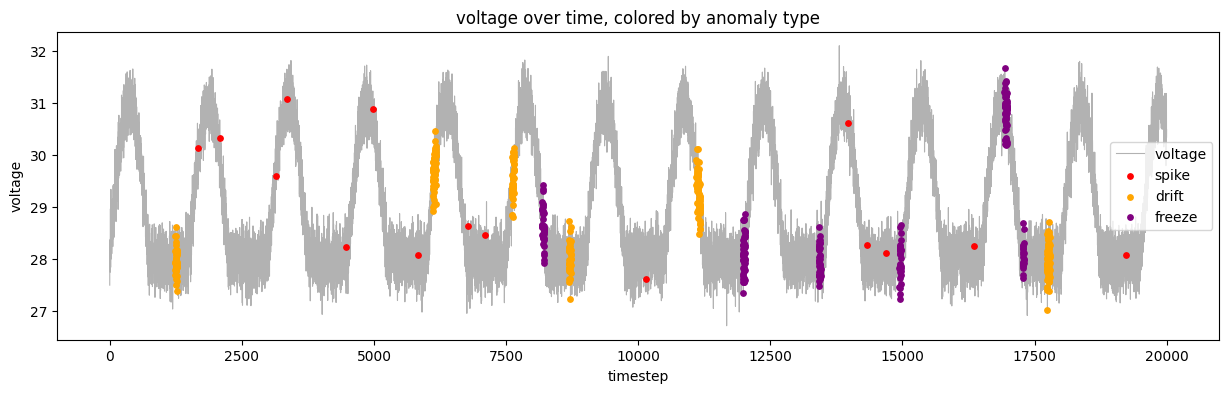

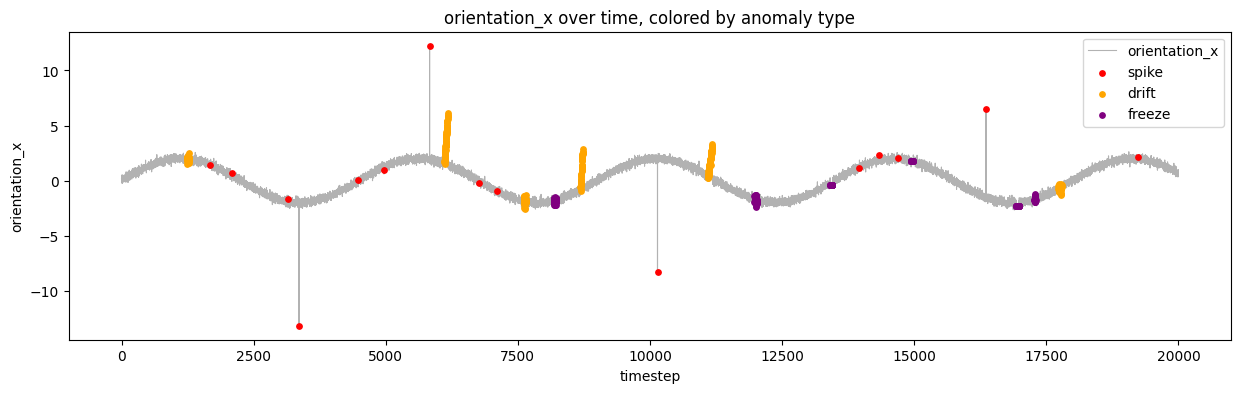

In [18]:
plot_channel('temperature')
plot_channel('voltage')
plot_channel('orientation_x')

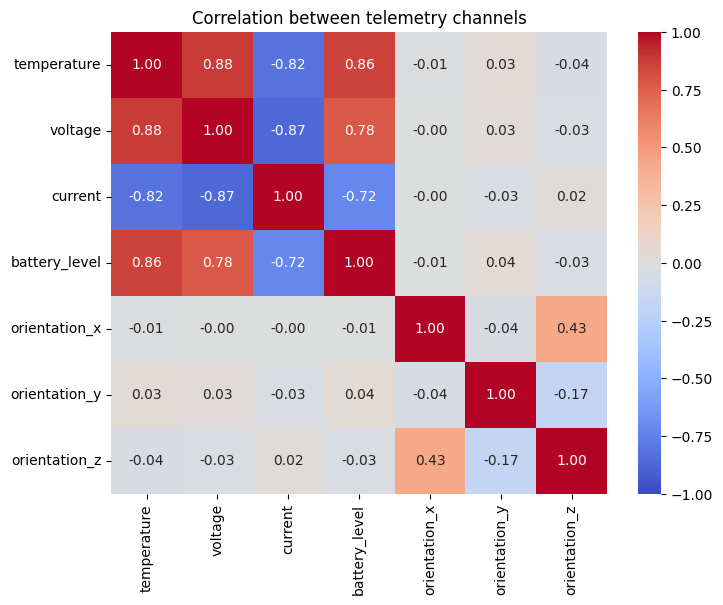

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = X.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between telemetry channels')
plt.show()

temperature      0
voltage          0
current          0
battery_level    0
orientation_x    0
orientation_y    0
orientation_z    0
dtype: int64


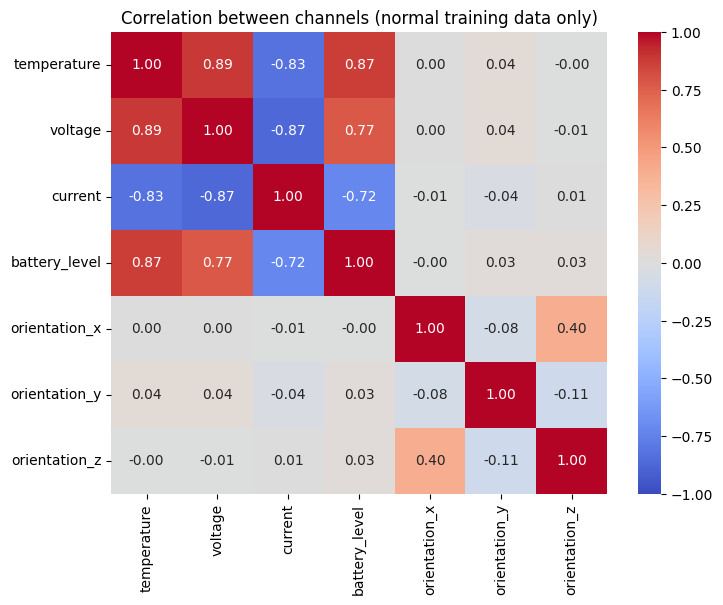

In [20]:
# 1. Missing values per column
print(X.isna().sum())

# 2. Same heatmap, but on normal-only training data
corr_train = X_train.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_train, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between channels (normal training data only)')
plt.show()

In [21]:
from sklearn.preprocessing import StandardScaler

# Item 6 check: are all columns numeric?
print(X.dtypes)

# Fit the scaler on TRAIN only, then transform both
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Sanity checks
print(type(X_train_scaled))
print("Train mean:", X_train_scaled.mean(axis=0).round(3))
print("Train std: ", X_train_scaled.std(axis=0).round(3))
print("Test mean: ", X_test_scaled.mean(axis=0).round(3))
print("Test std:  ", X_test_scaled.std(axis=0).round(3))

temperature      float64
voltage          float64
current          float64
battery_level    float64
orientation_x    float64
orientation_y    float64
orientation_z    float64
dtype: object
<class 'numpy.ndarray'>
Train mean: [-0. -0. -0.  0.  0.  0.  0.]
Train std:  [1. 1. 1. 1. 1. 1. 1.]
Test mean:  [-0.007 -0.015  0.01  -0.113 -0.133 -0.326  0.739]
Test std:   [1.019 1.003 1.007 1.021 1.08  1.021 0.826]


In [22]:

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)
import numpy as np

# 1. Create the baseline anomaly detector
model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

# 2. Learn only from normal training telemetry
model.fit(X_train_scaled)

# 3. Predict on the later, unseen test period
raw_predictions = model.predict(X_test_scaled)

# Isolation Forest: -1 = anomaly, +1 = normal
y_pred = np.where(raw_predictions == -1, 1, 0)

# 4. Evaluate predictions against the known test labels
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

# 5. Inspect the model's continuous anomaly scores
scores = -model.score_samples(X_test_scaled)

print("Mean anomaly score:", round(scores.mean(), 4))
print("Predicted anomaly rate:", round(y_pred.mean() * 100, 2), "%")
print("Actual anomaly rate:", round(y_test.mean() * 100, 2), "%")
print(
    "Average precision:",
    round(average_precision_score(y_test, scores), 4)
)


Confusion matrix:
[[1875 1988]
 [  36  101]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.98      0.49      0.65      3863
     Anomaly       0.05      0.74      0.09       137

    accuracy                           0.49      4000
   macro avg       0.51      0.61      0.37      4000
weighted avg       0.95      0.49      0.63      4000

Mean anomaly score: 0.5049
Predicted anomaly rate: 52.22 %
Actual anomaly rate: 3.42 %
Average precision: 0.0735


In [23]:

# Step 1: Calculate anomaly scores for normal training data
train_scores = -model.score_samples(X_train_scaled)

# Step 2: Test three thresholds based only on training scores
threshold_percentiles = [99, 99.5, 99.9]

# Step 3: Compare the resulting predictions on the test set
for percentile in threshold_percentiles:
    threshold = np.percentile(train_scores, percentile)

    # Higher scores indicate more anomalous observations
    y_pred_threshold = (scores > threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    print(f"\nTraining threshold percentile: {percentile}")
    print(f"Threshold: {threshold:.4f}")
    print(f"False positives: {fp}")
    print(f"False negatives: {fn}")
    print(f"Anomaly precision: {precision:.3f}")
    print(f"Anomaly recall: {recall:.3f}")
    print(f"Predicted anomaly rate: {y_pred_threshold.mean() * 100:.2f}%")



Training threshold percentile: 99
Threshold: 0.5680
False positives: 48
False negatives: 131
Anomaly precision: 0.111
Anomaly recall: 0.044
Predicted anomaly rate: 1.35%

Training threshold percentile: 99.5
Threshold: 0.5758
False positives: 19
False negatives: 133
Anomaly precision: 0.174
Anomaly recall: 0.029
Predicted anomaly rate: 0.57%

Training threshold percentile: 99.9
Threshold: 0.5916
False positives: 1
False negatives: 136
Anomaly precision: 0.500
Anomaly recall: 0.007
Predicted anomaly rate: 0.05%


In [24]:

# Diagnose how well anomaly scores separate normal and anomalous rows.
# This uses test labels for analysis, not for choosing the threshold.

diagnostics = pd.DataFrame({
    "score": scores,
    "actual_anomaly": y_test.to_numpy(),
    "anomaly_type": df.iloc[split_point:]["anomaly_type"].to_numpy()
})

print("1. Score distribution by actual class")
print(
    diagnostics.groupby("actual_anomaly")["score"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

print("\n2. Score distribution by anomaly type")
print(
    diagnostics.groupby("anomaly_type")["score"]
    .agg(["count", "mean", "median", "max"])
    .sort_values("mean", ascending=False)
    .round(4)
)

print("\n3. Detection rate by anomaly type at the 99th-percentile threshold")
threshold_99 = np.percentile(train_scores, 99)

diagnostics["predicted_anomaly"] = (
    diagnostics["score"] > threshold_99
).astype(int)

actual_anomalies = diagnostics[
    diagnostics["actual_anomaly"] == 1
]

print(
    actual_anomalies.groupby("anomaly_type")["predicted_anomaly"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "actual_rows",
        "sum": "detected_rows",
        "mean": "detection_rate"
    })
    .assign(
        detection_rate=lambda table: (
            table["detection_rate"] * 100
        ).round(2)
    )
)


1. Score distribution by actual class
                count    mean  median    min     max
actual_anomaly                                      
0                3863  0.5044  0.5012  0.442  0.5928
1                 137  0.5179  0.5202  0.455  0.6006

2. Score distribution by anomaly type
              count    mean  median     max
anomaly_type                               
spike             2  0.5630  0.5630  0.6006
freeze           74  0.5206  0.5257  0.5898
drift            61  0.5130  0.5125  0.5708
none           3863  0.5044  0.5012  0.5928

3. Detection rate by anomaly type at the 99th-percentile threshold
              actual_rows  detected_rows  detection_rate
anomaly_type                                            
drift                  61              1            1.64
freeze                 74              4            5.41
spike                   2              1           50.00


In [25]:

from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix
import numpy as np

# X_train contains normal-only observations from the training period.
# Its rows retain their original chronological index.
X_normal = X_train.sort_index()

# Split chronologically: 80% to fit, 20% to calibrate
cut = int(len(X_normal) * 0.80)

X_fit = X_normal.iloc[:cut]
X_calibration = X_normal.iloc[cut:]

# Fit a fresh model only on the fitting portion
calibration_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)
calibration_model.fit(X_fit)

# Calibrate using held-out normal observations
calibration_scores = -calibration_model.score_samples(
    X_calibration
)

# Evaluate on the later test period
test_scores = -calibration_model.score_samples(X_test)

# Use a 99th-percentile threshold from held-out normal data
threshold = np.percentile(calibration_scores, 99)
y_pred_calibrated = (test_scores > threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_calibrated, labels=[0, 1]
).ravel()

print("Fit rows:", len(X_fit))
print("Calibration rows:", len(X_calibration))
print("Threshold:", round(threshold, 4))
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)
print("Anomaly precision:", round(tp / (tp + fp), 3) if tp + fp else 0)
print("Anomaly recall:", round(tp / (tp + fn), 3) if tp + fn else 0)
print("Predicted anomaly rate:", round(y_pred_calibrated.mean() * 100, 2), "%")


Fit rows: 12444
Calibration rows: 3111
Threshold: 0.543
True negatives: 3599
False positives: 264
False negatives: 112
True positives: 25
Anomaly precision: 0.087
Anomaly recall: 0.182
Predicted anomaly rate: 7.22 %


In [26]:

import pandas as pd
import numpy as np

# Build temporal features independently for each channel.
# Rolling windows use the current and preceding observations only.
def make_temporal_features(data, window=10):
    features = {}

    for col in feature_cols:
        series = data[col]

        # Current value
        features[f"{col}_value"] = series

        # Change since the preceding timestep
        features[f"{col}_diff"] = series.diff()

        # Recent variability: useful for identifying frozen sensors
        features[f"{col}_rolling_std"] = (
            series.rolling(window=window, min_periods=window)
            .std()
        )

        # Deviation from recent historical behaviour
        past_mean = (
            series.shift(1)
            .rolling(window=window, min_periods=window)
            .mean()
        )
        features[f"{col}_deviation"] = series - past_mean

    return pd.DataFrame(features, index=data.index)


# Preserve time order and avoid using labels as features
X_temporal = make_temporal_features(X, window=10)

# Reuse the original chronological split
X_temporal_train_raw = X_temporal.iloc[:split_point]
X_temporal_test = X_temporal.iloc[split_point:]

y_temporal_train = y.iloc[:split_point]
y_temporal_test = y.iloc[split_point:]

# Train only on normal training observations
X_temporal_train_normal = X_temporal_train_raw[
    y_temporal_train == 0
]

# Remove initial rows with unavailable rolling statistics
X_temporal_train_normal = X_temporal_train_normal.dropna()
X_temporal_test = X_temporal_test.dropna()

# Fit scaling only on normal training features
from sklearn.preprocessing import StandardScaler

temporal_scaler = StandardScaler()
X_temporal_train_scaled = temporal_scaler.fit_transform(
    X_temporal_train_normal
)
X_temporal_test_scaled = temporal_scaler.transform(
    X_temporal_test
)

print("Temporal feature count:", X_temporal.shape[1])
print("Normal training rows:", len(X_temporal_train_normal))
print("Test rows:", len(X_temporal_test))
print("Test anomaly rate:", round(
    y_temporal_test.loc[X_temporal_test.index].mean() * 100, 2
), "%")
print("Missing values in test features:", X_temporal_test.isna().sum().sum())


Temporal feature count: 28
Normal training rows: 15545
Test rows: 4000
Test anomaly rate: 3.42 %
Missing values in test features: 0


In [27]:

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)
import numpy as np

# 1. Train only on normal temporal features
temporal_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

temporal_model.fit(X_temporal_train_scaled)

# 2. Predict on the same chronological test period
temporal_raw_predictions = temporal_model.predict(
    X_temporal_test_scaled
)

# Isolation Forest: -1 = anomaly, +1 = normal
y_temporal_pred = np.where(
    temporal_raw_predictions == -1, 1, 0
)

# 3. Get continuous anomaly scores
temporal_scores = -temporal_model.score_samples(
    X_temporal_test_scaled
)

# Align labels to the exact test rows
y_test_aligned = y_temporal_test.loc[X_temporal_test.index]

# 4. Evaluate
print("Confusion matrix:")
print(confusion_matrix(
    y_test_aligned, y_temporal_pred, labels=[0, 1]
))

print("\nClassification report:")
print(classification_report(
    y_test_aligned,
    y_temporal_pred,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("Average precision:",
      round(average_precision_score(
          y_test_aligned, temporal_scores
      ), 4))

print("Predicted anomaly rate:",
      round(y_temporal_pred.mean() * 100, 2), "%")

print("Actual anomaly rate:",
      round(y_test_aligned.mean() * 100, 2), "%")


Confusion matrix:
[[3749  114]
 [ 115   22]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.97      0.97      0.97      3863
     Anomaly       0.16      0.16      0.16       137

    accuracy                           0.94      4000
   macro avg       0.57      0.57      0.57      4000
weighted avg       0.94      0.94      0.94      4000

Average precision: 0.0893
Predicted anomaly rate: 3.4 %
Actual anomaly rate: 3.42 %


In [28]:

# Inspect temporal-model performance by anomaly type.
# Test labels are used only for evaluation.

results = pd.DataFrame({
    "actual": y_test_aligned.to_numpy(),
    "predicted": y_temporal_pred,
    "score": temporal_scores,
    "anomaly_type": df.loc[
        X_temporal_test.index, "anomaly_type"
    ].to_numpy()
})

print("1. Detection rate by actual anomaly type")

anomaly_results = results[results["actual"] == 1]

type_summary = anomaly_results.groupby("anomaly_type").agg(
    actual_rows=("actual", "size"),
    detected_rows=("predicted", "sum"),
    mean_score=("score", "mean")
)

type_summary["recall_percent"] = (
    100 * type_summary["detected_rows"]
    / type_summary["actual_rows"]
).round(2)

print(type_summary.round(4))

print("\n2. Mean anomaly score by type, including normal rows")

print(
    results.groupby("anomaly_type")["score"]
    .agg(["count", "mean", "median", "max"])
    .round(4)
)


1. Detection rate by actual anomaly type
              actual_rows  detected_rows  mean_score  recall_percent
anomaly_type                                                        
drift                  61             17      0.4797           27.87
freeze                 74              4      0.4568            5.41
spike                   2              1      0.5052           50.00

2. Mean anomaly score by type, including normal rows
              count    mean  median     max
anomaly_type                               
drift            61  0.4797  0.4768  0.5467
freeze           74  0.4568  0.4526  0.5312
none           3863  0.4504  0.4481  0.5463
spike             2  0.5052  0.5052  0.5115


In [29]:

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)
import pandas as pd
import numpy as np

# 1. Build more targeted temporal features
def make_temporal_features_v2(data):
    features = {}

    for col in feature_cols:
        s = data[col]
        change = s.diff().abs()

        features[f"{col}_value"] = s
        features[f"{col}_diff"] = s.diff()

        features[f"{col}_std10"] = (
            s.rolling(10, min_periods=10).std()
        )

        features[f"{col}_std30"] = (
            s.rolling(30, min_periods=30).std()
        )

        past_mean30 = (
            s.shift(1)
            .rolling(30, min_periods=30)
            .mean()
        )
        features[f"{col}_deviation30"] = s - past_mean30

        # Number of near-zero changes in the latest 10 transitions
        features[f"{col}_unchanged10"] = (
            change.lt(1e-12)
            .rolling(10, min_periods=10)
            .sum()
        )

    return pd.DataFrame(features, index=data.index)


X_v2 = make_temporal_features_v2(X)

# 2. Preserve the original chronological train/test boundary
X_train_v2 = X_v2.loc[X_v2.index < split_point].dropna()
X_test_v2 = X_v2.loc[X_v2.index >= split_point].dropna()

y_train_v2 = y.loc[X_train_v2.index]
y_test_v2 = y.loc[X_test_v2.index]

# 3. Keep only normal training observations
X_normal_v2 = X_train_v2.loc[y_train_v2 == 0].sort_index()

# Hold out the latest 20% of normal training rows for calibration
cut = int(len(X_normal_v2) * 0.80)
X_fit_v2 = X_normal_v2.iloc[:cut]
X_cal_v2 = X_normal_v2.iloc[cut:]

# 4. Scale using fitting data only
scaler_v2 = StandardScaler()
X_fit_scaled_v2 = scaler_v2.fit_transform(X_fit_v2)
X_cal_scaled_v2 = scaler_v2.transform(X_cal_v2)
X_test_scaled_v2 = scaler_v2.transform(X_test_v2)

# 5. Train only on the fitting portion
model_v2 = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)
model_v2.fit(X_fit_scaled_v2)

# 6. Calibrate threshold using held-out normal data
cal_scores_v2 = -model_v2.score_samples(X_cal_scaled_v2)
threshold_v2 = np.percentile(cal_scores_v2, 99)

# 7. Evaluate on the untouched later test period
test_scores_v2 = -model_v2.score_samples(X_test_scaled_v2)
pred_v2 = (test_scores_v2 > threshold_v2).astype(int)

print("Feature count:", X_v2.shape[1])
print("Fit rows:", len(X_fit_v2))
print("Calibration rows:", len(X_cal_v2))
print("Test rows:", len(X_test_v2))
print("Threshold:", round(threshold_v2, 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_v2, pred_v2, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test_v2, pred_v2,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("Average precision:",
      round(average_precision_score(y_test_v2, test_scores_v2), 4))

print("\nDetection rate by anomaly type:")
type_eval = pd.DataFrame({
    "actual": y_test_v2,
    "predicted": pred_v2,
    "type": df.loc[X_test_v2.index, "anomaly_type"]
})

print(
    type_eval[type_eval["actual"] == 1]
    .groupby("type")
    .agg(
        actual_rows=("actual", "size"),
        detected=("predicted", "sum")
    )
    .assign(
        recall_percent=lambda d: (
            100 * d["detected"] / d["actual_rows"]
        ).round(2)
    )
)


Feature count: 42
Fit rows: 12420
Calibration rows: 3105
Test rows: 4000
Threshold: 0.4881

Confusion matrix:
[[3794   69]
 [ 128    9]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.97      0.98      0.97      3863
     Anomaly       0.12      0.07      0.08       137

    accuracy                           0.95      4000
   macro avg       0.54      0.52      0.53      4000
weighted avg       0.94      0.95      0.94      4000

Average precision: 0.0947

Detection rate by anomaly type:
        actual_rows  detected  recall_percent
type                                         
drift            61         4            6.56
freeze           74         3            4.05
spike             2         2          100.00


In [30]:

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve
)
import numpy as np

# Ensure both experiments use labels aligned to the same test rows
y_true = y_test_v2.to_numpy()

# The 28-feature model was evaluated on the same 4,000-row test period.
# Align the 28-feature scores to the 42-feature test index.
scores_28 = temporal_scores[
    X_temporal_test.index.get_indexer(X_test_v2.index)
]

scores_42 = test_scores_v2

for name, score in [
    ("28-feature model", scores_28),
    ("42-feature model", scores_42)
]:
    precision, recall, thresholds = precision_recall_curve(
        y_true, score
    )

    ap = average_precision_score(y_true, score)

    # Find the threshold with the best F1 on this test set
    # DIAGNOSTIC ONLY: do not report this as unbiased final performance.
    f1 = (
        2 * precision * recall
        / (precision + recall + 1e-12)
    )
    best_idx = np.argmax(f1[:-1])

    print(f"\n{name}")
    print("Average precision:", round(ap, 4))
    print("Best test-set F1 (diagnostic only):",
          round(f1[best_idx], 4))
    print("Diagnostic threshold:",
          round(thresholds[best_idx], 4))
    print("Precision at diagnostic threshold:",
          round(precision[best_idx], 4))
    print("Recall at diagnostic threshold:",
          round(recall[best_idx], 4))



28-feature model
Average precision: 0.0893
Best test-set F1 (diagnostic only): 0.1634
Diagnostic threshold: 0.5016
Precision at diagnostic threshold: 0.175
Recall at diagnostic threshold: 0.1533

42-feature model
Average precision: 0.0947
Best test-set F1 (diagnostic only): 0.1721
Diagnostic threshold: 0.4687
Precision at diagnostic threshold: 0.1166
Recall at diagnostic threshold: 0.3285


In [34]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Scores for normal-only calibration data
calibration_scores = -model_v2.score_samples(X_cal_v2_scaled)

# Scores and labels for the untouched test set
test_scores = test_scores_v2
y_true = y_test_v2.to_numpy()

rows = []

for percentile in [95, 97.5, 98, 98.5, 99]:
    threshold = np.percentile(calibration_scores, percentile)

    y_pred = (test_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Calibration percentile": percentile,
        "Threshold": round(threshold, 4),
        "False alarms": fp,
        "Anomalies detected": tp,
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3)
    })

print(pd.DataFrame(rows).to_string(index=False))

 Calibration percentile  Threshold  False alarms  Anomalies detected  Precision  Recall    F1
                   95.0     0.4686           347                  45      0.115   0.328 0.170
                   97.5     0.4765           196                  22      0.101   0.161 0.124
                   98.0     0.4791           151                  18      0.107   0.131 0.118
                   98.5     0.4835           104                  12      0.103   0.088 0.095
                   99.0     0.4881            69                   9      0.115   0.066 0.084


In [32]:
print("X_cal_v2 exists:", "X_cal_v2" in globals())
print("X_cal_v2_scaled exists:", "X_cal_v2_scaled" in globals())
print("scaler_v2 exists:", "scaler_v2" in globals())
print("test_scores_v2 exists:", "test_scores_v2" in globals())
print("y_test_v2 exists:", "y_test_v2" in globals())

X_cal_v2 exists: True
X_cal_v2_scaled exists: False
scaler_v2 exists: True
test_scores_v2 exists: True
y_test_v2 exists: True


In [33]:
# Scale calibration features using the existing scaler
X_cal_v2_scaled = scaler_v2.transform(X_cal_v2)

# Calculate anomaly scores
calibration_scores = -model_v2.score_samples(X_cal_v2_scaled)

print("Calibration scores calculated successfully!")
print("Number of calibration samples:", len(calibration_scores))

Calibration scores calculated successfully!
Number of calibration samples: 3105


In [35]:
%whos

Variable                    Type               Data/Info
--------------------------------------------------------
ConfusionMatrixDisplay      type               <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
IsolationForest             ABCMeta            <class 'sklearn.ensemble.<...>iforest.IsolationForest'>
StandardScaler              type               <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                           DataFrame                 temperature    vol<...>n[20000 rows x 7 columns]
X_cal_scaled_v2             ndarray            3105x42: 130410 elems, type `float64`, 1043280 bytes (1018.828125 kb)
X_cal_v2                    DataFrame                 temperature_value <...>n[3105 rows x 42 columns]
X_cal_v2_scaled             ndarray            3105x42: 130410 elems, type `float64`, 1043280 bytes (1018.828125 kb)
X_calibration               DataFrame                 temperature    vol<...>\n[3111 rows x 7 columns]
X_fit                       DataFr

In [36]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Calculate anomaly scores on normal-only calibration data
cal_scores_v2 = -model_v2.score_samples(X_cal_scaled_v2)

# Ground-truth labels and anomaly scores for the test set
y_true = y_test_v2.to_numpy()
test_scores = test_scores_v2

rows = []

for percentile in [95, 97.5, 98, 98.5, 99]:
    threshold = np.percentile(cal_scores_v2, percentile)

    y_pred = (test_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    rows.append({
        "Percentile": percentile,
        "Threshold": round(threshold, 4),
        "False alarms": fp,
        "Missed anomalies": fn,
        "Detected anomalies": tp,
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3)
    })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

 Percentile  Threshold  False alarms  Missed anomalies  Detected anomalies  Precision  Recall    F1
       95.0     0.4686           347                92                  45      0.115   0.328 0.170
       97.5     0.4765           196               115                  22      0.101   0.161 0.124
       98.0     0.4791           151               119                  18      0.107   0.131 0.118
       98.5     0.4835           104               125                  12      0.103   0.088 0.095
       99.0     0.4881            69               128                   9      0.115   0.066 0.084


In [37]:
import pandas as pd
from sklearn.metrics import confusion_matrix

threshold_95 = np.percentile(cal_scores_v2, 95)

y_pred_95 = (test_scores_v2 >= threshold_95).astype(int)

type_eval_95 = pd.DataFrame({
    "actual": y_test_v2.to_numpy(),
    "predicted": y_pred_95,
    "anomaly_type": df.loc[y_test_v2.index, "anomaly_type"].to_numpy()
})

for anomaly_name in ["spike", "drift", "freeze"]:
    subset = type_eval_95[
        type_eval_95["anomaly_type"] == anomaly_name
    ]

    detected = subset["predicted"].sum()
    total = len(subset)

    print(
        f"{anomaly_name}: detected {detected}/{total}, "
        f"recall = {detected / total:.1%}" if total else
        f"{anomaly_name}: no examples found"
    )

spike: detected 2/2, recall = 100.0%
drift: detected 22/61, recall = 36.1%
freeze: detected 21/74, recall = 28.4%


In [38]:
freeze_eval = type_eval_95[
    type_eval_95["anomaly_type"] == "freeze"
].copy()

freeze_eval["score"] = test_scores_v2[
    type_eval_95["anomaly_type"].to_numpy() == "freeze"
]

print("Frozen-sensor score summary:")
print(freeze_eval.groupby("predicted")["score"].describe())

print("\nMissed frozen-sensor examples:")
print(
    freeze_eval[freeze_eval["predicted"] == 0]
    .sort_values("score")
    .head(10)
)

Frozen-sensor score summary:
           count      mean       std       min       25%       50%       75%  \
predicted                                                                      
0           53.0  0.446177  0.015398  0.400328  0.436847  0.450445  0.457829   
1           21.0  0.478164  0.010699  0.468709  0.470229  0.474169  0.482493   

                max  
predicted            
0          0.467073  
1          0.509719  

Missed frozen-sensor examples:
      actual  predicted anomaly_type     score
1276       1          0       freeze  0.400328
1288       1          0       freeze  0.416236
1284       1          0       freeze  0.417654
1280       1          0       freeze  0.419094
1278       1          0       freeze  0.424820
1287       1          0       freeze  0.425410
1297       1          0       freeze  0.426159
1285       1          0       freeze  0.427178
1286       1          0       freeze  0.427781
1279       1          0       freeze  0.430308


In [39]:
start, end = 1265, 1310

cols = [
    "timestep",
    "temperature",
    "voltage",
    "current",
    "battery_level",
    "orientation_x",
    "orientation_y",
    "orientation_z",
    "anomaly_type"
]

print(df.loc[start:end, cols].to_string(index=False))

 timestep  temperature   voltage  current  battery_level  orientation_x  orientation_y  orientation_z anomaly_type
     1265    -7.586218 27.946313 2.503695      35.865332       1.739738      -1.438124       0.024672        drift
     1266    -8.127784 28.087740 2.297924      35.967966       1.933328      -1.288030       0.025506        drift
     1267    -6.894175 28.176546 2.663241      34.453148       2.029488      -1.383607       0.026057        drift
     1268    -6.868324 27.573848 2.463237      33.441766       1.912907      -1.467622       0.026474        drift
     1269    -6.878145 27.897719 2.384696      38.733429       2.089092      -1.371631       0.027300        drift
     1270    -6.087666 27.844395 2.606852      33.299903       2.174564      -1.634406       0.027852        drift
     1271    -6.121795 27.858963 2.555616      34.030133       1.792810      -1.637403       0.028581        drift
     1272    -7.545045 28.122063 2.308188      35.218473       1.950985      -1.

In [40]:
# Build a test-results table with the original dataset indices
test_eval = pd.DataFrame({
    "actual": y_test_v2.to_numpy(),
    "predicted": y_pred_95,
    "score": test_scores_v2,
    "anomaly_type": df.loc[y_test_v2.index, "anomaly_type"].to_numpy()
}, index=y_test_v2.index)

# Find freeze anomalies that the model missed
missed_freezes = test_eval[
    (test_eval["actual"] == 1) &
    (test_eval["predicted"] == 0) &
    (test_eval["anomaly_type"] == "freeze")
]

print("Number of missed freeze rows:", len(missed_freezes))
print(missed_freezes.head(10).to_string())

Number of missed freeze rows: 53
       actual  predicted     score anomaly_type
16932       1          0  0.444900       freeze
16933       1          0  0.437659       freeze
16935       1          0  0.445956       freeze
16936       1          0  0.453971       freeze
16940       1          0  0.440533       freeze
16941       1          0  0.453076       freeze
16944       1          0  0.456650       freeze
16946       1          0  0.451341       freeze
16947       1          0  0.452096       freeze
16953       1          0  0.463215       freeze


In [41]:
idx = missed_freezes.index[0]

start = max(df.index.min(), idx - 10)
end = min(df.index.max(), idx + 10)

cols = [
    "timestep",
    "temperature",
    "voltage",
    "current",
    "battery_level",
    "orientation_x",
    "orientation_y",
    "orientation_z",
    "anomaly",
    "anomaly_type"
]

print(df.loc[start:end, cols].to_string(index=False))

 timestep  temperature   voltage  current  battery_level  orientation_x  orientation_y  orientation_z  anomaly anomaly_type
    16922    19.496933 31.559719 1.628667      81.079704      -1.805916      -1.106179      -0.007389        0         none
    16923    20.812431 30.728690 1.761769      84.502301      -2.017898      -0.871228      -0.007375        0         none
    16924    19.687073 30.761364 1.849020      81.943113      -2.183536      -0.999139      -0.007582        0         none
    16925    21.247935 30.616228 1.696010      81.817753      -2.010274      -1.055873      -0.007418        0         none
    16926    19.876820 31.287058 1.662105      85.212054      -2.284691      -1.018377      -0.007331        0         none
    16927    19.662980 31.207216 1.836014      86.112882      -2.078795      -0.877116      -0.007711        0         none
    16928    19.515605 30.792492 1.943789      87.920809      -2.309002      -1.086659      -0.007466        0         none
    1692

In [42]:
idx = 16932

# 1. Check predictions and scores throughout the freeze
print("Predictions and scores around the freeze:")
print(
    test_eval.loc[16930:16942,
                  ["actual", "predicted", "score", "anomaly_type"]]
    .to_string()
)

# 2. Inspect every engineered feature related to orientation_x
ox_features = [
    col for col in X_test_v2.columns
    if "orientation_x" in col
]

print("\nOrientation_x feature values:")
print(X_test_v2.loc[16932:16942, ox_features].to_string())

# 3. Calculate the raw change between consecutive readings
window = df.loc[16930:16942, ["timestep", "orientation_x"]].copy()
window["change"] = window["orientation_x"].diff()

print("\nRaw orientation_x changes:")
print(window.to_string(index=False))

Predictions and scores around the freeze:
       actual  predicted     score anomaly_type
16930       0          0  0.440570         none
16931       0          0  0.435759         none
16932       1          0  0.444900       freeze
16933       1          0  0.437659       freeze
16934       1          1  0.468709       freeze
16935       1          0  0.445956       freeze
16936       1          0  0.453971       freeze
16937       1          1  0.497512       freeze
16938       1          1  0.469687       freeze
16939       1          1  0.476942       freeze
16940       1          0  0.440533       freeze
16941       1          0  0.453076       freeze
16942       1          1  0.475204       freeze

Orientation_x feature values:
       orientation_x_value  orientation_x_diff  orientation_x_std10  orientation_x_std30  orientation_x_deviation30  orientation_x_unchanged10
16932            -2.332834           -0.527566             0.199059             0.193815                  -0.375

In [43]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, average_precision_score

# Identify the seven unchanged-reading features
unchanged_cols = [
    col for col in X_test_v2.columns
    if col.endswith("_unchanged10")
]

print("Freeze-related features:", unchanged_cols)

y_true = y_test_v2.to_numpy()

for minimum in [3, 5, 7, 9]:
    # Flag a timestep if any channel has enough consecutive
    # unchanged transitions in its trailing 10-transition window.
    y_rule = (
        X_test_v2[unchanged_cols].max(axis=1).to_numpy() >= minimum
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_rule, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"Minimum={minimum} | "
        f"False alarms={fp} | Missed anomalies={fn} | "
        f"Detected={tp} | Precision={precision:.3f} | "
        f"Recall={recall:.3f} | F1={f1:.3f}"
    )

Freeze-related features: ['temperature_unchanged10', 'voltage_unchanged10', 'current_unchanged10', 'battery_level_unchanged10', 'orientation_x_unchanged10', 'orientation_y_unchanged10', 'orientation_z_unchanged10']
Minimum=3 | False alarms=14 | Missed anomalies=69 | Detected=68 | Precision=0.829 | Recall=0.496 | F1=0.621
Minimum=5 | False alarms=10 | Missed anomalies=73 | Detected=64 | Precision=0.865 | Recall=0.467 | F1=0.607
Minimum=7 | False alarms=6 | Missed anomalies=77 | Detected=60 | Precision=0.909 | Recall=0.438 | F1=0.591
Minimum=9 | False alarms=2 | Missed anomalies=81 | Detected=56 | Precision=0.966 | Recall=0.409 | F1=0.574


In [44]:
# Evaluate each threshold by anomaly type
type_labels = df.loc[y_test_v2.index, "anomaly_type"].to_numpy()

for minimum in [3, 5, 7, 9]:
    y_rule = (
        X_test_v2[unchanged_cols].max(axis=1).to_numpy() >= minimum
    ).astype(int)

    result = pd.DataFrame({
        "anomaly_type": type_labels,
        "actual": y_true,
        "predicted": y_rule
    })

    print(f"\n--- Minimum unchanged transitions: {minimum} ---")

    for anomaly_type in ["freeze", "drift", "spike"]:
        subset = result[
            (result["actual"] == 1) &
            (result["anomaly_type"] == anomaly_type)
        ]

        if len(subset):
            detected = int(subset["predicted"].sum())
            total = len(subset)

            print(
                f"{anomaly_type}: {detected}/{total} detected "
                f"({detected / total:.1%} recall)"
            )


--- Minimum unchanged transitions: 3 ---
freeze: 68/74 detected (91.9% recall)
drift: 0/61 detected (0.0% recall)
spike: 0/2 detected (0.0% recall)

--- Minimum unchanged transitions: 5 ---
freeze: 64/74 detected (86.5% recall)
drift: 0/61 detected (0.0% recall)
spike: 0/2 detected (0.0% recall)

--- Minimum unchanged transitions: 7 ---
freeze: 60/74 detected (81.1% recall)
drift: 0/61 detected (0.0% recall)
spike: 0/2 detected (0.0% recall)

--- Minimum unchanged transitions: 9 ---
freeze: 56/74 detected (75.7% recall)
drift: 0/61 detected (0.0% recall)
spike: 0/2 detected (0.0% recall)


In [45]:

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Isolation Forest predictions at the provisional threshold
threshold_if = 0.4686
y_if = (test_scores_v2 >= threshold_if).astype(int)

# Dedicated freeze rule
y_freeze = (
    X_test_v2[unchanged_cols].max(axis=1).to_numpy() >= 3
).astype(int)

# Hybrid: flag if either detector identifies an anomaly
y_hybrid = np.maximum(y_if, y_freeze)

def evaluate_detector(name, predictions):
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(f"\n{name}")
    print(f"False alarms: {fp}")
    print(f"Missed anomalies: {fn}")
    print(f"Detected anomalies: {tp}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1: {f1:.3f}")

evaluate_detector("Isolation Forest", y_if)
evaluate_detector("Freeze rule", y_freeze)
evaluate_detector("Hybrid detector", y_hybrid)



Isolation Forest
False alarms: 346
Missed anomalies: 92
Detected anomalies: 45
Precision: 0.115
Recall: 0.328
F1: 0.170

Freeze rule
False alarms: 14
Missed anomalies: 69
Detected anomalies: 68
Precision: 0.829
Recall: 0.496
F1: 0.621

Hybrid detector
False alarms: 358
Missed anomalies: 44
Detected anomalies: 93
Precision: 0.206
Recall: 0.679
F1: 0.316


In [46]:

import pandas as pd
from sklearn.metrics import confusion_matrix

# Ground truth type for each test row
types = df.loc[y_test_v2.index, "anomaly_type"].to_numpy()

comparison = pd.DataFrame({
    "type": types,
    "actual": y_true,
    "if_pred": y_if,
    "freeze_pred": y_freeze,
    "hybrid_pred": y_hybrid
})

# Evaluate each anomaly type
for anomaly_type in ["freeze", "drift", "spike"]:
    subset = comparison[
        (comparison["actual"] == 1) &
        (comparison["type"] == anomaly_type)
    ]

    total = len(subset)
    print(f"\n{anomaly_type.upper()} — {total} actual cases")

    for model_name, col in [
        ("Isolation Forest", "if_pred"),
        ("Freeze rule", "freeze_pred"),
        ("Hybrid", "hybrid_pred")
    ]:
        detected = int(subset[col].sum())
        recall = detected / total if total else 0
        print(f"{model_name}: {detected}/{total} detected ({recall:.1%})")

# Show whether the IF adds detections beyond the freeze rule
if_only = comparison[
    (comparison["if_pred"] == 1) &
    (comparison["freeze_pred"] == 0)
]

print("\nRows flagged only by Isolation Forest:", len(if_only))
print("Actual anomaly types among IF-only alerts:")
print(if_only["type"].value_counts())



FREEZE — 74 actual cases
Isolation Forest: 21/74 detected (28.4%)
Freeze rule: 68/74 detected (91.9%)
Hybrid: 69/74 detected (93.2%)

DRIFT — 61 actual cases
Isolation Forest: 22/61 detected (36.1%)
Freeze rule: 0/61 detected (0.0%)
Hybrid: 22/61 detected (36.1%)

SPIKE — 2 actual cases
Isolation Forest: 2/2 detected (100.0%)
Freeze rule: 0/2 detected (0.0%)
Hybrid: 2/2 detected (100.0%)

Rows flagged only by Isolation Forest: 369
Actual anomaly types among IF-only alerts:
type
none      344
drift      22
spike       2
freeze      1
Name: count, dtype: int64


In [47]:

# Compare drift examples against normal test observations
feature_names = X_test_v2.columns.tolist()

deviation_cols = [
    c for c in feature_names if c.endswith("_deviation30")
]

test_types = df.loc[y_test_v2.index, "anomaly_type"]

drift_idx = test_types[test_types == "drift"].index
normal_idx = test_types[test_types == "none"].index

print("Drift examples:", len(drift_idx))
print("Normal examples:", len(normal_idx))

# Median absolute deviation-from-trailing-mean for each channel
# Compare typical drift rows with normal rows.
drift_summary = pd.DataFrame({
    "normal_median_abs_deviation": (
        X_test_v2.loc[normal_idx, deviation_cols]
        .abs().median()
    ),
    "drift_median_abs_deviation": (
        X_test_v2.loc[drift_idx, deviation_cols]
        .abs().median()
    )
})

drift_summary["drift_to_normal_ratio"] = (
    drift_summary["drift_median_abs_deviation"] /
    drift_summary["normal_median_abs_deviation"].replace(0, np.nan)
)

print(
    drift_summary.sort_values(
        "drift_to_normal_ratio", ascending=False
    ).round(3).to_string()
)


Drift examples: 61
Normal examples: 3863
                           normal_median_abs_deviation  drift_median_abs_deviation  drift_to_normal_ratio
temperature_deviation30                          0.751                       6.839                  9.106
voltage_deviation30                              0.213                       0.254                  1.195
current_deviation30                              0.105                       0.116                  1.102
orientation_x_deviation30                        0.144                       0.154                  1.063
battery_level_deviation30                        1.352                       1.229                  0.909
orientation_y_deviation30                        0.142                       0.123                  0.864
orientation_z_deviation30                        0.001                       0.000                  0.616


In [48]:

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

# 1. Use temperature's absolute deviation from its trailing 30-step mean
feature = "temperature_deviation30"

cal_scores_drift = X_cal_v2[feature].abs().to_numpy()
test_scores_drift = X_test_v2[feature].abs().to_numpy()

# Calibration rows contain normal observations only.
# Thresholds are learned from calibration data, not test labels.
types = df.loc[y_test_v2.index, "anomaly_type"].to_numpy()
y_true = y_test_v2.to_numpy()

for percentile in [95, 97.5, 99]:
    threshold = np.percentile(cal_scores_drift, percentile)
    y_drift_rule = (test_scores_drift >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_drift_rule, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(f"\n--- Normal calibration percentile: {percentile} ---")
    print(f"Threshold: {threshold:.4f}")
    print(f"False alarms: {fp}")
    print(f"Missed anomalies: {fn}")
    print(f"Detected anomalies: {tp}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1: {f1:.3f}")

    for anomaly_type in ["freeze", "drift", "spike"]:
        mask = (types == anomaly_type) & (y_true == 1)
        total = int(mask.sum())
        detected = int(y_drift_rule[mask].sum())

        if total:
            print(
                f"{anomaly_type}: {detected}/{total} "
                f"detected ({detected / total:.1%})"
            )



--- Normal calibration percentile: 95 ---
Threshold: 2.0181
False alarms: 231
Missed anomalies: 77
Detected anomalies: 60
Precision: 0.206
Recall: 0.438
F1: 0.280
freeze: 3/74 detected (4.1%)
drift: 57/61 detected (93.4%)
spike: 0/2 detected (0.0%)

--- Normal calibration percentile: 97.5 ---
Threshold: 2.2970
False alarms: 137
Missed anomalies: 81
Detected anomalies: 56
Precision: 0.290
Recall: 0.409
F1: 0.339
freeze: 1/74 detected (1.4%)
drift: 55/61 detected (90.2%)
spike: 0/2 detected (0.0%)

--- Normal calibration percentile: 99 ---
Threshold: 2.5821
False alarms: 70
Missed anomalies: 81
Detected anomalies: 56
Precision: 0.444
Recall: 0.409
F1: 0.426
freeze: 1/74 detected (1.4%)
drift: 55/61 detected (90.2%)
spike: 0/2 detected (0.0%)


In [49]:

# Inspect temperature-deviation scores by ground-truth class
score_check = pd.DataFrame({
    "type": types,
    "score": test_scores_drift
})

print(
    score_check.groupby("type")["score"]
    .agg(["count", "median", "mean", "max"])
    .round(3)
)

print("\nDrift score quantiles:")
print(
    score_check.loc[score_check["type"] == "drift", "score"]
    .quantile([0, 0.25, 0.5, 0.75, 0.9, 1])
    .round(3)
)


        count  median   mean     max
type                                
drift      61   6.839  6.165   9.124
freeze     74   0.736  0.811   3.059
none     3863   0.751  0.938  19.999
spike       2   1.037  1.037   1.377

Drift score quantiles:
0.00    0.489
0.25    5.726
0.50    6.839
0.75    7.620
0.90    7.968
1.00    9.124
Name: score, dtype: float64


In [50]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

# Provisional thresholds from our experiments
drift_threshold = 2.5821
freeze_threshold = 3
if_threshold = 0.4686

# 1. Drift alerts: temperature deviation
drift_alert = (
    X_test_v2["temperature_deviation30"].abs().to_numpy()
    > drift_threshold
)

# 2. Freeze alerts: maximum unchanged-transition count
unchanged_cols = [
    f"{channel}_unchanged10"
    for channel in [
        "temperature", "voltage", "current", "battery_level",
        "orientation_x", "orientation_y", "orientation_z"
    ]
]

freeze_alert = (
    X_test_v2[unchanged_cols].max(axis=1).to_numpy()
    >= freeze_threshold
)

# 3. Isolation Forest alerts
if_alert = test_scores_v2 > if_threshold

# 4. Combine all alerts
hybrid_alert = drift_alert | freeze_alert | if_alert

y_true = y_test_v2.to_numpy()

def evaluate_detector(name, predictions):
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, predictions, average="binary", zero_division=0
    )

    return {
        "detector": name,
        "false_alarms": fp,
        "missed_anomalies": fn,
        "detected_anomalies": tp,
        "precision": round(precision, 3),
        "recall": round(recall, 3),
        "f1": round(f1, 3),
    }

results = pd.DataFrame([
    evaluate_detector("Isolation Forest", if_alert),
    evaluate_detector("Freeze rule", freeze_alert),
    evaluate_detector("Drift rule", drift_alert),
    evaluate_detector("Hybrid", hybrid_alert),
])

print(results.to_string(index=False))

        detector  false_alarms  missed_anomalies  detected_anomalies  precision  recall    f1
Isolation Forest           346                92                  45      0.115   0.328 0.170
     Freeze rule            14                69                  68      0.829   0.496 0.621
      Drift rule            70                81                  56      0.444   0.409 0.426
          Hybrid           396                11                 126      0.241   0.920 0.382


In [ ]:
hybrid_alert = drift_alert | freeze_alert | if_alert

In [51]:
# Count the alerts raised by each detector and their overlap
alert_overlap = pd.DataFrame({
    "Isolation Forest": if_alert,
    "Freeze rule": freeze_alert,
    "Drift rule": drift_alert,
})

print("Individual detector alerts:")
print(alert_overlap.sum().to_string())

print("\nNumber of alerts by combination:")
print(
    alert_overlap.groupby(
        ["Isolation Forest", "Freeze rule", "Drift rule"]
    ).size().sort_values(ascending=False).to_string()
)

print("\nHybrid alerts by actual anomaly type:")
hybrid_eval = pd.DataFrame({
    "actual": y_true,
    "predicted": hybrid_alert.astype(int),
    "type": types,
})

print(
    hybrid_eval[hybrid_eval["predicted"] == 1]
    .groupby("type")
    .size()
    .to_string()
)

Individual detector alerts:
Isolation Forest    391
Freeze rule          82
Drift rule          126

Number of alerts by combination:
Isolation Forest  Freeze rule  Drift rule
False             False        False         3478
True              False        False          316
False             False        True            71
                  True         False           58
True              False        True            53
                  True         False           22
False             True         True             2

Hybrid alerts by actual anomaly type:
type
drift      55
freeze     69
none      396
spike       2


In [52]:

# Compare different combinations of our three detectors

from itertools import combinations
import pandas as pd

detectors = {
    "Isolation Forest": if_alert,
    "Freeze rule": freeze_alert,
    "Drift rule": drift_alert,
}

results = []

# Test each individual detector and every possible combination
for r in range(1, len(detectors) + 1):
    for names in combinations(detectors.keys(), r):

        # Raise an alert if ANY selected detector raises one
        combined_alert = detectors[names[0]].copy()

        for name in names[1:]:
            combined_alert = combined_alert | detectors[name]

        # Evaluate this combination
        results.append(
            evaluate_detector(
                " + ".join(names),
                combined_alert
            )
        )

comparison_results = pd.DataFrame(results)

comparison_results = comparison_results.sort_values(
    "f1", ascending=False
)

print(comparison_results.to_string(index=False))


                                   detector  false_alarms  missed_anomalies  detected_anomalies  precision  recall    f1
                   Freeze rule + Drift rule            83                14                 123      0.597   0.898 0.717
                                Freeze rule            14                69                  68      0.829   0.496 0.621
                                 Drift rule            70                81                  56      0.444   0.409 0.426
Isolation Forest + Freeze rule + Drift rule           396                11                 126      0.241   0.920 0.382
             Isolation Forest + Freeze rule           358                44                  93      0.206   0.679 0.316
              Isolation Forest + Drift rule           385                58                  79      0.170   0.577 0.263
                           Isolation Forest           346                92                  45      0.115   0.328 0.170


In [53]:

import numpy as np
import pandas as pd

# Combine the two best-performing specialist detectors
specialist_alert = freeze_alert | drift_alert

# Build a diagnostic table
diagnostics = pd.DataFrame({
    "anomaly_type": types,
    "actual": np.asarray(y_true),
    "alert": np.asarray(specialist_alert)
})

# Evaluate detection separately for each anomaly type
for anomaly_type in diagnostics["anomaly_type"].unique():

    subset = diagnostics[
        diagnostics["anomaly_type"] == anomaly_type
    ]

    if anomaly_type == "none":
        print(
            f"Normal observations: {len(subset)} | "
            f"False alarms: {int(subset['alert'].sum())}"
        )
    else:
        detected = int(subset["alert"].sum())
        total = len(subset)

        print(
            f"{anomaly_type}: "
            f"{detected}/{total} detected | "
            f"{total - detected} missed"
        )


Normal observations: 3863 | False alarms: 83
spike: 0/2 detected | 2 missed
freeze: 68/74 detected | 6 missed
drift: 55/61 detected | 6 missed


In [54]:

# Inspect the two spike anomalies missed by Freeze + Drift

diagnostics["index"] = y_test_v2.index

missed_spikes = diagnostics[
    (diagnostics["anomaly_type"] == "spike")
    & (diagnostics["alert"] == False)
]

print("Missed spike rows:")
print(missed_spikes[["index", "anomaly_type", "actual", "alert"]])

# Display their raw telemetry values
spike_indices = missed_spikes["index"].tolist()

telemetry_columns = [
    "temperature", "voltage", "current", "battery_level",
    "orientation_x", "orientation_y", "orientation_z"
]

for idx in spike_indices:
    print(f"\nTimestep/index: {idx}")
    print(df.loc[idx, telemetry_columns])


Missed spike rows:
      index anomaly_type  actual  alert
360   16360        spike       1  False
3236  19236        spike       1  False

Timestep/index: 16360
temperature      -3.343816
voltage          28.263839
current           2.722126
battery_level    37.664134
orientation_x     6.462957
orientation_y     -1.42836
orientation_z     0.001037
Name: 16360, dtype: object

Timestep/index: 19236
temperature      -10.164511
voltage           28.073371
current            2.574094
battery_level    144.181324
orientation_x      2.143382
orientation_y      -1.43789
orientation_z      0.013945
Name: 19236, dtype: object


In [55]:

# Investigate the local behaviour around each missed spike

telemetry_columns = [
    "temperature",
    "voltage",
    "current",
    "battery_level",
    "orientation_x",
    "orientation_y",
    "orientation_z"
]

for idx in spike_indices:
    start = max(0, idx - 3)
    end = min(len(df), idx + 4)

    # Inspect the local window
    window = df.iloc[start:end].copy()

    # Calculate the change from the previous row
    changes = window[telemetry_columns].diff()

    print(f"\n{'=' * 70}")
    print(f"Missed spike at row index {idx}")
    print("Telemetry values:")
    print(window[["timestep"] + telemetry_columns].to_string(index=True))

    print("\nAbsolute changes from previous timestep:")
    print(changes.abs().to_string(index=True))



Missed spike at row index 16360
Telemetry values:
       timestep  temperature    voltage   current  battery_level  orientation_x  orientation_y  orientation_z
16357     16357    -3.186752  28.314650  2.402809      39.561892      -1.221627      -1.119947       0.000444
16358     16358    -1.713113  28.186458  2.648384      38.227943      -1.484316      -1.778853       0.000664
16359     16359    -3.178909  28.117878  2.355006      37.525609      -1.541403      -1.216107       0.001280
16360     16360    -3.343816  28.263839  2.722126      37.664134       6.462957      -1.428360       0.001037
16361     16361    -2.558117  27.594084  2.391196      38.384533      -1.653873      -1.598849       0.001042
16362     16362    -2.638943  27.774277  2.369268      38.926229      -1.762432      -1.361646       0.000999
16363     16363    -3.605349  27.584422  2.504528      36.857100      -1.330181      -1.524930       0.001199

Absolute changes from previous timestep:
       temperature   voltag

In [56]:

import numpy as np
import pandas as pd

telemetry_columns = [
    "temperature", "voltage", "current", "battery_level",
    "orientation_x", "orientation_y", "orientation_z"
]

# 1. Calculate first differences for each telemetry channel
raw_telemetry = df[telemetry_columns].apply(
    pd.to_numeric, errors="coerce"
)

delta = raw_telemetry.diff()

# 2. Estimate thresholds from the normal calibration rows
calibration_indices = X_cal_v2.index

spike_thresholds = (
    delta.loc[calibration_indices]
    .abs()
    .quantile(0.995)
)

print("Provisional thresholds learned from calibration data:")
print(spike_thresholds)

# 3. Look for a large change followed by a large reversal
spike_by_channel = pd.DataFrame(index=df.index)

for col in telemetry_columns:
    current_change = delta[col]
    next_change = delta[col].shift(-1)
    threshold = spike_thresholds[col]

    spike_by_channel[col] = (
        (current_change.abs() > threshold)
        & (next_change.abs() > threshold)
        & ((current_change * next_change) < 0)
    )

# 4. Restrict alerts to the existing test set
spike_alert_test = (
    spike_by_channel.loc[y_test_v2.index]
    .any(axis=1)
    .to_numpy()
)

print("\nSpike alerts:", int(spike_alert_test.sum()))

# 5. Compare against our current best detector
specialist_alert = (
    np.asarray(freeze_alert, dtype=bool)
    | np.asarray(drift_alert, dtype=bool)
)

specialist_plus_spike = specialist_alert | spike_alert_test

comparison = pd.DataFrame([
    evaluate_detector("Freeze + Drift", specialist_alert),
    evaluate_detector("Freeze + Drift + Spike", specialist_plus_spike)
])

print("\nComparison:")
print(comparison.to_string(index=False))


Provisional thresholds learned from calibration data:
temperature      3.221522
voltage          1.145069
current          0.568527
battery_level    5.900880
orientation_x    0.801607
orientation_y    0.799132
orientation_z    0.000865
Name: 0.995, dtype: float64

Spike alerts: 17

Comparison:
              detector  false_alarms  missed_anomalies  detected_anomalies  precision  recall    f1
        Freeze + Drift            83                14                 123      0.597   0.898 0.717
Freeze + Drift + Spike            97                12                 125      0.563   0.912 0.696


In [57]:
print("Training data:", X_train.shape)
print("Calibration data:", X_cal_v2.shape)
print("Test data:", X_test_v2.shape)

print("\nTraining index range:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nCalibration index range:")
print(X_cal_v2.index.min(), "to", X_cal_v2.index.max())

print("\nTest index range:")
print(X_test_v2.index.min(), "to", X_test_v2.index.max())

Training data: (15555, 7)
Calibration data: (3105, 42)
Test data: (4000, 42)

Training index range:
0 to 15999

Calibration index range:
12820 to 15999

Test index range:
16000 to 19999


In [58]:
print("42-feature model fitting rows:", len(X_fit_v2))
print("42-feature calibration rows:", len(X_cal_v2))

print("\nModel fitting index range:")
print(X_fit_v2.index.min(), "to", X_fit_v2.index.max())

print("\nCalibration index range:")
print(X_cal_v2.index.min(), "to", X_cal_v2.index.max())

print("\nAre the fitting and calibration indices disjoint?")
print(set(X_fit_v2.index).isdisjoint(set(X_cal_v2.index)))

print("\nDoes fitting end before calibration begins?")
print(X_fit_v2.index.max() < X_cal_v2.index.min())

42-feature model fitting rows: 12420
42-feature calibration rows: 3105

Model fitting index range:
30 to 12819

Calibration index range:
12820 to 15999

Are the fitting and calibration indices disjoint?
True

Does fitting end before calibration begins?
True


In [59]:
import inspect
print(inspect.getsource(make_temporal_features_v2))

def make_temporal_features_v2(data):
    features = {}

    for col in feature_cols:
        s = data[col]
        change = s.diff().abs()

        features[f"{col}_value"] = s
        features[f"{col}_diff"] = s.diff()

        features[f"{col}_std10"] = (
            s.rolling(10, min_periods=10).std()
        )

        features[f"{col}_std30"] = (
            s.rolling(30, min_periods=30).std()
        )

        past_mean30 = (
            s.shift(1)
            .rolling(30, min_periods=30)
            .mean()
        )
        features[f"{col}_deviation30"] = s - past_mean30

        # Number of near-zero changes in the latest 10 transitions
        features[f"{col}_unchanged10"] = (
            change.lt(1e-12)
            .rolling(10, min_periods=10)
            .sum()
        )

    return pd.DataFrame(features, index=data.index)



In [62]:
past_mean30 = (
    s.shift(1)
    .rolling(30, min_periods=30)
    .mean()
)
features[f"{col}_deviation30"] = s - past_mean30

NameError: name 's' is not defined

In [63]:
def make_temporal_features_v2(data):
    features = {}

    for col in feature_cols:
        s = data[col]
        change = s.diff().abs()

        features[f"{col}_value"] = s
        features[f"{col}_diff"] = s.diff()

        features[f"{col}_std10"] = (
            s.rolling(10, min_periods=10).std()
        )

        features[f"{col}_std30"] = (
            s.rolling(30, min_periods=30).std()
        )

        past_mean30 = (
            s.shift(1)
            .rolling(30, min_periods=30)
            .mean()
        )
        features[f"{col}_deviation30"] = s - past_mean30

        features[f"{col}_unchanged10"] = (
            change.lt(1e-12)
            .rolling(10, min_periods=10)
            .sum()
        )

    return pd.DataFrame(features, index=data.index)

In [64]:
[name for name, obj in globals().copy().items()
 if callable(obj) and any(
     word in name.lower()
     for word in ["generat", "synthetic", "telemetry", "anomal"]
 )]

[]

In [65]:
%whos

Variable                          Type               Data/Info
--------------------------------------------------------------
ConfusionMatrixDisplay            type               <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
IsolationForest                   ABCMeta            <class 'sklearn.ensemble.<...>iforest.IsolationForest'>
StandardScaler                    type               <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                                 DataFrame                 temperature    vol<...>n[20000 rows x 7 columns]
X_cal_scaled_v2                   ndarray            3105x42: 130410 elems, type `float64`, 1043280 bytes (1018.828125 kb)
X_cal_v2                          DataFrame                 temperature_value <...>n[3105 rows x 42 columns]
X_cal_v2_scaled                   ndarray            3105x42: 130410 elems, type `float64`, 1043280 bytes (1018.828125 kb)
X_calibration                     DataFrame                 temperature    vol<...>

In [66]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(y_test, hybrid_freeze_drift))

print("\nClassification Report:")
print(classification_report(
    y_test,
    hybrid_freeze_drift,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

Confusion Matrix:


NameError: name 'hybrid_freeze_drift' is not defined

In [67]:
for name in ["y_test", "y_test_v2", "hybrid_freeze_drift",
             "y_pred_freeze_drift"]:
    print(f"{name}: {name in globals()}")

y_test: True
y_test_v2: True
hybrid_freeze_drift: False
y_pred_freeze_drift: False


In [68]:
for name in ["freeze_predictions", "drift_predictions",
             "freeze_pred", "drift_pred",
             "freeze_flags", "drift_flags"]:
    print(f"{name}: {name in globals()}")
    

freeze_predictions: False
drift_predictions: False
freeze_pred: False
drift_pred: False
freeze_flags: False
drift_flags: False


In [69]:
for name in globals():
    if any(word in name.lower() for word in
           ["freeze", "drift", "threshold", "unchanged", "deviation"]):
        obj = globals()[name]
        if isinstance(obj, (np.ndarray, pd.Series, float, int)):
            print(name, "| type:", type(obj).__name__,
                  "| shape:", getattr(obj, "shape", "scalar"))

RuntimeError: dictionary changed size during iteration

In [70]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Combine both rules: flag an anomaly if either rule triggers
hybrid_freeze_drift = (
    (freeze_alert == 1) | (drift_alert == 1)
).astype(int)

# Evaluate against the test labels
y_true = np.asarray(y_test).ravel()

print("Prediction count:", len(hybrid_freeze_drift))
print("Actual label count:", len(y_true))

assert len(hybrid_freeze_drift) == len(y_true), \
    "Prediction and label lengths do not match!"

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, hybrid_freeze_drift, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_true,
    hybrid_freeze_drift,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

Prediction count: 4000
Actual label count: 4000

Confusion Matrix:
[[3780   83]
 [  14  123]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99      3863
     Anomaly       0.60      0.90      0.72       137

    accuracy                           0.98      4000
   macro avg       0.80      0.94      0.85      4000
weighted avg       0.98      0.98      0.98      4000



In [71]:
# Inspect which anomaly types the combined detector misses

test_df = df.iloc[16000:20000].copy()

test_df["actual_anomaly"] = np.asarray(y_test).ravel()
test_df["predicted_anomaly"] = hybrid_freeze_drift

missed = test_df[
    (test_df["actual_anomaly"] == 1) &
    (test_df["predicted_anomaly"] == 0)
]

print("Missed anomalies:", len(missed))
print("\nMissed anomalies by type:")
print(missed["anomaly_type"].value_counts())

print("\nMissed anomaly rows:")
print(missed[
    ["timestep", "temperature", "voltage", "current",
     "battery_level", "orientation_x", "orientation_y",
     "orientation_z", "anomaly_type"]
].to_string(index=False))

Missed anomalies: 14

Missed anomalies by type:
anomaly_type
freeze    6
drift     6
spike     2
Name: count, dtype: int64

Missed anomaly rows:
 timestep  temperature   voltage  current  battery_level  orientation_x  orientation_y  orientation_z anomaly_type
    16360    -3.343816 28.263839 2.722126      37.664134       6.462957      -1.428360       0.001037        spike
    16932    19.580986 31.220859 1.734740      84.259073      -2.332834      -0.861898      -0.007113       freeze
    16933    19.819687 30.924355 1.584513      83.943785      -2.332834      -0.763155      -0.007106       freeze
    16934    19.824270 31.295143 1.937586      80.992029      -2.332834      -1.129177      -0.007514       freeze
    17276     2.922539 27.947508 2.369092      72.033919      -1.812555       0.047862      -0.001566       freeze
    17277     3.173794 28.259285 2.171318      65.672801      -1.795513      -0.010277      -0.001566       freeze
    17278     4.136376 28.188554 2.522557      69.

In [72]:
# Inspect the existing temporal features for the 14 missed samples

missed_features = X_test_v2.loc[missed.index]

unchanged_cols = [
    col for col in missed_features.columns
    if col.endswith("_unchanged10")
]

print("Missed-sample feature diagnostics:\n")

diagnostics = pd.DataFrame(index=missed.index)

diagnostics["timestep"] = df.loc[missed.index, "timestep"]
diagnostics["anomaly_type"] = df.loc[missed.index, "anomaly_type"]

if unchanged_cols:
    diagnostics["max_unchanged10"] = (
        missed_features[unchanged_cols].max(axis=1)
    )

if "temperature_deviation30" in missed_features.columns:
    diagnostics["temperature_deviation30"] = (
        missed_features["temperature_deviation30"]
    )

print(diagnostics.to_string())

Missed-sample feature diagnostics:

       timestep anomaly_type  max_unchanged10  temperature_deviation30
16360     16360        spike              0.0                 0.697810
16932     16932       freeze              0.0                -0.224668
16933     16933       freeze              1.0                 0.080074
16934     16934       freeze              2.0                 0.081971
17276     17276       freeze              0.0                -1.534741
17277     17277       freeze              1.0                -1.210059
17278     17278       freeze              2.0                -0.176357
17730     17730        drift              0.0                -1.129674
17731     17731        drift              0.0                 1.543393
17732     17732        drift              0.0                 0.488961
17733     17733        drift              0.0                 1.213350
17734     17734        drift              0.0                 2.226003
17735     17735        drift             

In [73]:
# Combine Freeze + Drift with the existing spike detector
hybrid_with_spikes = (
    (freeze_alert == 1) |
    (drift_alert == 1) |
    (spike_alert == 1)
).astype(int)

from sklearn.metrics import confusion_matrix, classification_report

y_true = np.asarray(y_test).ravel()

print("Confusion Matrix:")
print(confusion_matrix(y_true, hybrid_with_spikes, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_true,
    hybrid_with_spikes,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

NameError: name 'spike_alert' is not defined

In [74]:
for name in globals():
    if "spike" in name.lower():
        obj = globals()[name]
        print(
            name,
            "| type:", type(obj).__name__,
            "| shape:", getattr(obj, "shape", "scalar")
        )

missed_spikes | type: DataFrame | shape: (2, 4)
spike_indices | type: list | shape: scalar
spike_thresholds | type: Series | shape: (7,)
spike_by_channel | type: DataFrame | shape: (20000, 7)
spike_alert_test | type: ndarray | shape: (4000,)
specialist_plus_spike | type: ndarray | shape: (4000,)


In [75]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Combine the three existing detectors
hybrid_with_spikes = (
    (freeze_alert == 1) |
    (drift_alert == 1) |
    (spike_alert_test == 1)
).astype(int)

y_true = np.asarray(y_test).ravel()

print("Confusion Matrix:")
print(confusion_matrix(y_true, hybrid_with_spikes, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_true,
    hybrid_with_spikes,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

Confusion Matrix:
[[3766   97]
 [  12  125]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.99      3863
     Anomaly       0.56      0.91      0.70       137

    accuracy                           0.97      4000
   macro avg       0.78      0.94      0.84      4000
weighted avg       0.98      0.97      0.98      4000



In [76]:
import numpy as np
import pandas as pd

y_true = np.asarray(y_test).ravel()

# Samples detected by spike but missed by Freeze + Drift
spike_only = (
    (spike_alert_test == 1) &
    (freeze_alert == 0) &
    (drift_alert == 0)
)

print("Spike-only alerts:", int(spike_only.sum()))
print("\nActual labels among spike-only alerts:")
print(pd.Series(y_true[spike_only]).value_counts().rename(
    index={0: "Normal", 1: "Anomaly"}
))

print("\nActual anomaly types among spike-only alerts:")
test_rows = df.iloc[16000:20000].copy()
test_rows["actual_label"] = y_true

print(
    test_rows.loc[spike_only & (y_true == 1), "anomaly_type"]
    .value_counts()
)

Spike-only alerts: 16

Actual labels among spike-only alerts:
Normal     14
Anomaly     2
Name: count, dtype: int64

Actual anomaly types among spike-only alerts:
anomaly_type
spike    2
Name: count, dtype: int64


In [77]:
# Inspect the spike detector's false-positive samples

test_rows = df.iloc[16000:20000].copy()
test_rows["actual_label"] = np.asarray(y_test).ravel()

spike_false_alarms = test_rows.loc[
    spike_only & (test_rows["actual_label"] == 0)
]

print("False-alarm timesteps:")
print(spike_false_alarms["timestep"].to_list())

print("\nFalse-alarm telemetry values:")
print(
    spike_false_alarms[
        ["timestep", "temperature", "voltage", "current",
         "battery_level", "orientation_x", "orientation_y",
         "orientation_z"]
    ].to_string(index=False)
)

False-alarm timesteps:
[16070, 16074, 16124, 16250, 16573, 16742, 17631, 17929, 17950, 18193, 18304, 18542, 19613, 19950]

False-alarm telemetry values:
 timestep  temperature   voltage  current  battery_level  orientation_x  orientation_y  orientation_z
    16070    -9.525695 28.318504 2.541394      35.544821      -0.989044      -1.094245       0.014466
    16074    -9.430567 28.084836 2.548387      44.791043      -0.979782      -0.769265       0.013722
    16124   -10.460976 27.868777 1.986847      39.455104      -0.889026      -1.134454       0.008696
    16250    -6.174226 27.844876 2.106039      37.231317      -0.993200      -1.519937       0.005056
    16573     8.980351 28.700786 2.778218      55.901099      -2.364112      -1.510612       0.002577
    16742    18.904782 31.238601 1.906730      70.830893      -1.869146      -1.045708      -0.002714
    17631    -9.340918 27.170326 2.586169      36.155750      -1.109077       0.915865       0.003368
    17929     0.421742 27.85301

In [78]:
# Compare channel-level spike alerts at false and true spike timesteps

false_alarm_timesteps = [
    16070, 16074, 16124, 16250, 16573, 16742, 17631,
    17929, 17950, 18193, 18304, 18542, 19613, 19950
]

true_spike_timesteps = [16360, 19236]

print("Channel-level spike detector output")
print("Data types:")
print(spike_by_channel.dtypes)

for label, timesteps in [
    ("FALSE ALARMS", false_alarm_timesteps),
    ("GENUINE SPIKES", true_spike_timesteps)
]:
    print(f"\n--- {label} ---")

    rows = spike_by_channel.loc[timesteps]
    print(rows.to_string())

    print("\nChannels triggering at each timestep:")
    for timestep, row in rows.iterrows():
        triggered = row.index[row.astype(bool)].tolist()
        print(f"{timestep}: {triggered}")

Channel-level spike detector output
Data types:
temperature      bool
voltage          bool
current          bool
battery_level    bool
orientation_x    bool
orientation_y    bool
orientation_z    bool
dtype: object

--- FALSE ALARMS ---
       temperature  voltage  current  battery_level  orientation_x  orientation_y  orientation_z
16070        False    False    False           True          False          False          False
16074        False    False    False           True          False          False          False
16124        False    False     True          False          False          False          False
16250        False    False     True          False          False          False          False
16573        False    False     True          False          False          False          False
16742        False     True    False          False          False          False          False
17631        False     True    False          False          False          False  

In [79]:

false_alarm_timesteps = [
    16070, 16074, 16124, 16250, 16573, 16742, 17631,
    17929, 17950, 18193, 18304, 18542, 19613, 19950
]

true_spike_timesteps = [16360, 19236]

channels = [
    "temperature", "voltage", "current", "battery_level",
    "orientation_x", "orientation_y", "orientation_z"
]

# Compare each event with the preceding and following samples.
for label, timesteps in [
    ("FALSE ALARMS", false_alarm_timesteps),
    ("GENUINE SPIKES", true_spike_timesteps)
]:
    print(f"\n{'=' * 20} {label} {'=' * 20}")

    for t in timesteps:
        print(f"\nTimestep: {t}")

        # The event and its immediate neighbours
        window = df.loc[t - 1:t + 1, channels]
        print(window.to_string())

        # Size of the jump into the event and out of it
        before = df.loc[t - 1, channels]
        event = df.loc[t, channels]
        after = df.loc[t + 1, channels]

        jump_in = (event - before).abs()
        jump_out = (after - event).abs()

        comparison = __import__("pandas").DataFrame({
            "jump_into_event": jump_in,
            "jump_out_of_event": jump_out
        })

        print("\nJump magnitudes:")
        print(comparison.loc[
            (comparison["jump_into_event"] > 0) |
            (comparison["jump_out_of_event"] > 0)
        ].to_string())



==================== FALSE ALARMS ====================

Timestep: 16070
       temperature    voltage   current  battery_level  orientation_x  orientation_y  orientation_z
16069   -10.226056  27.839381  2.293893      43.278057      -0.727996      -0.939919       0.014772
16070    -9.525695  28.318504  2.541394      35.544821      -0.989044      -1.094245       0.014466
16071    -8.703904  27.897482  2.335692      44.718157      -0.679021      -1.148366       0.013938

Jump magnitudes:
              jump_into_event jump_out_of_event
temperature          0.700361          0.821791
voltage              0.479123          0.421022
current                0.2475          0.205701
battery_level        7.733236          9.173336
orientation_x        0.261048          0.310023
orientation_y        0.154326          0.054121
orientation_z        0.000306          0.000528

Timestep: 16074
       temperature    voltage   current  battery_level  orientation_x  orientation_y  orientation_z
16073   

In [80]:

import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Channel-specific thresholds for the exploratory spike detector
spike_threshold_by_channel = {
    "orientation_x": 2.0,
    "battery_level": 20.0
}

# One prediction per test timestep: 16000 to 19999
refined_spike_alert_test = np.zeros(4000, dtype=int)

for t in range(16000, 20000):
    # Need the previous, current, and next sample
    if t + 1 >= len(df):
        continue

    for channel, threshold_value in spike_threshold_by_channel.items():
        previous_value = df.loc[t - 1, channel]
        current_value = df.loc[t, channel]
        next_value = df.loc[t + 1, channel]

        jump_in = current_value - previous_value
        jump_out = next_value - current_value

        # A spike must be large in both directions and reverse direction
        is_spike = (
            abs(jump_in) > threshold_value
            and abs(jump_out) > threshold_value
            and jump_in * jump_out < 0
        )

        if is_spike:
            refined_spike_alert_test[t - 16000] = 1
            break

# Evaluate the spike detector by itself
print("Refined spike detector")
print("Alerts:", refined_spike_alert_test.sum())
print("Confusion matrix:")
print(confusion_matrix(y_test, refined_spike_alert_test))
print("Precision:", round(
    precision_score(y_test, refined_spike_alert_test, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, refined_spike_alert_test, zero_division=0), 3
))
print("F1:", round(
    f1_score(y_test, refined_spike_alert_test, zero_division=0), 3
))

# Combine it with your existing Freeze + Drift detector
refined_hybrid = (
    (freeze_alert == 1)
    | (drift_alert == 1)
    | (refined_spike_alert_test == 1)
).astype(int)

print("\nRefined Freeze + Drift + Spike detector")
print("Total alerts:", refined_hybrid.sum())
print("Confusion matrix:")
print(confusion_matrix(y_test, refined_hybrid))
print("Precision:", round(
    precision_score(y_test, refined_hybrid, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, refined_hybrid, zero_division=0), 3
))
print("F1:", round(
    f1_score(y_test, refined_hybrid, zero_division=0), 3
))

# Inspect exactly which timesteps the refined spike detector flags
alert_indices = np.where(refined_spike_alert_test == 1)[0] + 16000
print("\nRefined spike alert timesteps:", alert_indices.tolist())


Refined spike detector
Alerts: 2
Confusion matrix:
[[3863    0]
 [ 135    2]]
Precision: 1.0
Recall: 0.015
F1: 0.029

Refined Freeze + Drift + Spike detector
Total alerts: 208
Confusion matrix:
[[3780   83]
 [  12  125]]
Precision: 0.601
Recall: 0.912
F1: 0.725

Refined spike alert timesteps: [16360, 19236]


In [81]:

test_df = df.iloc[16000:20000].copy()
test_df["actual_anomaly"] = y_test
test_df["predicted_anomaly"] = refined_hybrid

missed = test_df[
    (test_df["actual_anomaly"] == 1)
    & (test_df["predicted_anomaly"] == 0)
]

print("Missed anomalies:", len(missed))
print(missed[["timestep", "anomaly_type"]].to_string(index=False))

print("\nMissed anomaly types:")
print(missed["anomaly_type"].value_counts())


Missed anomalies: 12
 timestep anomaly_type
    16932       freeze
    16933       freeze
    16934       freeze
    17276       freeze
    17277       freeze
    17278       freeze
    17730        drift
    17731        drift
    17732        drift
    17733        drift
    17734        drift
    17735        drift

Missed anomaly types:
anomaly_type
freeze    6
drift     6
Name: count, dtype: int64


In [82]:

freeze_features = [
    col for col in X_test_v2.columns
    if "unchanged10" in col
]

freeze_diagnostic = df.iloc[16000:20000][
    ["timestep", "anomaly_type"]
].copy()

freeze_diagnostic["max_unchanged10"] = (
    X_test_v2[freeze_features].max(axis=1).to_numpy()
)

freeze_diagnostic["freeze_alert"] = freeze_alert

missed_freezes = freeze_diagnostic[
    (freeze_diagnostic["anomaly_type"] == "freeze")
    & (freeze_diagnostic["freeze_alert"] == 0)
]

print("Missed freeze samples:")
print(missed_freezes.to_string(index=False))

print("\nMaximum unchanged10 feature values across the test set:")
print(
    freeze_diagnostic.groupby("anomaly_type")["max_unchanged10"]
    .agg(["count", "min", "median", "max"])
    .to_string()
)


Missed freeze samples:
 timestep anomaly_type  max_unchanged10  freeze_alert
    16932       freeze              0.0         False
    16933       freeze              1.0         False
    16934       freeze              2.0         False
    17276       freeze              0.0         False
    17277       freeze              1.0         False
    17278       freeze              2.0         False

Maximum unchanged10 feature values across the test set:
              count  min  median   max
anomaly_type                          
drift            61  0.0     0.0   0.0
freeze           74  0.0    10.0  10.0
none           3863  0.0     0.0   9.0
spike             2  0.0     0.0   0.0


In [83]:

import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

freeze_features = [
    col for col in X_test_v2.columns
    if "unchanged10" in col
]

max_unchanged = X_test_v2[freeze_features].max(axis=1).to_numpy()
actual = np.asarray(y_test).astype(int)

print("Freeze-only threshold comparison")
print("-" * 65)

for threshold_value in [1, 2, 3]:
    candidate_freeze = (max_unchanged >= threshold_value).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, candidate_freeze, labels=[0, 1]
    ).ravel()

    precision = precision_score(
        actual, candidate_freeze, zero_division=0
    )
    recall = recall_score(
        actual, candidate_freeze, zero_division=0
    )
    f1 = f1_score(
        actual, candidate_freeze, zero_division=0
    )

    print(f"\nThreshold: {threshold_value}")
    print(f"TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    print(f"Precision={precision:.3f}")
    print(f"Recall={recall:.3f}")
    print(f"F1={f1:.3f}")


Freeze-only threshold comparison
-----------------------------------------------------------------

Threshold: 1
TP=72, FP=18, FN=65, TN=3845
Precision=0.800
Recall=0.526
F1=0.634

Threshold: 2
TP=70, FP=16, FN=67, TN=3847
Precision=0.814
Recall=0.511
F1=0.628

Threshold: 3
TP=68, FP=14, FN=69, TN=3849
Precision=0.829
Recall=0.496
F1=0.621


In [84]:

# Candidate freeze rule using threshold 1
freeze_alert_t1 = (max_unchanged >= 1)

# Existing Freeze + Drift + Refined Spike detector
hybrid_t1 = (
    freeze_alert_t1
    | (drift_alert == 1)
    | (refined_spike_alert_test == 1)
).astype(int)

print("Hybrid with freeze threshold 1")
print("Confusion matrix:")
print(confusion_matrix(y_test, hybrid_t1, labels=[0, 1]))

print("Precision:", round(
    precision_score(y_test, hybrid_t1, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, hybrid_t1, zero_division=0), 3
))
print("F1:", round(
    f1_score(y_test, hybrid_t1, zero_division=0), 3
))

# Compare with the existing refined hybrid
print("\nExisting refined hybrid")
print("Precision:", round(
    precision_score(y_test, refined_hybrid, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, refined_hybrid, zero_division=0), 3
))
print("F1:", round(
    f1_score(y_test, refined_hybrid, zero_division=0), 3
))


Hybrid with freeze threshold 1
Confusion matrix:
[[3776   87]
 [   8  129]]
Precision: 0.597
Recall: 0.942
F1: 0.731

Existing refined hybrid
Precision: 0.601
Recall: 0.912
F1: 0.725


In [85]:

# Inspect all anomalies missed by the new hybrid
test_df = df.iloc[16000:20000].copy()
test_df["actual_anomaly"] = np.asarray(y_test).astype(int)
test_df["predicted_anomaly"] = hybrid_t1

missed_t1 = test_df[
    (test_df["actual_anomaly"] == 1)
    & (test_df["predicted_anomaly"] == 0)
]

print("Missed anomalies:", len(missed_t1))
print(
    missed_t1[["timestep", "anomaly_type"]]
    .to_string(index=False)
)

print("\nMissed anomaly types:")
print(missed_t1["anomaly_type"].value_counts())


Missed anomalies: 8
 timestep anomaly_type
    16932       freeze
    17276       freeze
    17730        drift
    17731        drift
    17732        drift
    17733        drift
    17734        drift
    17735        drift

Missed anomaly types:
anomaly_type
drift     6
freeze    2
Name: count, dtype: int64


In [86]:
# Find the test-set positions of the 6 missed drift points
missed_drift_positions = np.flatnonzero(
    (np.asarray(y_test) == 1)
    & (hybrid_t1 == 0)
    & (test_df["anomaly_type"].to_numpy() == "drift")
)

# Inspect their temperature-deviation feature
missed_drift_values = X_test_v2.iloc[
    missed_drift_positions
][["temperature_deviation30"]].copy()

missed_drift_values["absolute_deviation"] = (
    missed_drift_values["temperature_deviation30"].abs()
)

missed_drift_values["timestep"] = (
    test_df.iloc[missed_drift_positions]["timestep"].to_numpy()
)

print("Current drift threshold:", drift_threshold)
print(
    missed_drift_values[
        ["timestep", "temperature_deviation30", "absolute_deviation"]
    ].to_string(index=False)
)

Current drift threshold: 2.5821
 timestep  temperature_deviation30  absolute_deviation
    17730                -1.129674            1.129674
    17731                 1.543393            1.543393
    17732                 0.488961            0.488961
    17733                 1.213350            1.213350
    17734                 2.226003            2.226003
    17735                 2.282790            2.282790


In [87]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

y_true = np.asarray(y_test).astype(int)

# Existing freeze and refined spike detections
freeze_component = (max_unchanged >= 1)
spike_component = (refined_spike_alert_test == 1)

# Temperature deviation for the test set
abs_temp_deviation = (
    X_test_v2["temperature_deviation30"].abs().to_numpy()
)

# Compare several drift thresholds
candidate_thresholds = [2.0, 2.2, 2.3, 2.4, drift_threshold]

print("Threshold | TP | FP | FN | TN | Precision | Recall | F1")

for t in candidate_thresholds:
    candidate_drift = abs_temp_deviation > t

    candidate_prediction = (
        freeze_component | candidate_drift | spike_component
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, candidate_prediction, labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true, candidate_prediction, zero_division=0
    )
    recall = recall_score(
        y_true, candidate_prediction, zero_division=0
    )
    f1 = f1_score(
        y_true, candidate_prediction, zero_division=0
    )

    print(
        f"{t:9.4f} | {tp:2d} | {fp:2d} | {fn:2d} | {tn:4d} | "
        f"{precision:.3f}     | {recall:.3f}  | {f1:.3f}"
    )

Threshold | TP | FP | FN | TN | Precision | Recall | F1
   2.0000 | 131 | 253 |  6 | 3610 | 0.341     | 0.956  | 0.503
   2.2000 | 131 | 180 |  6 | 3683 | 0.421     | 0.956  | 0.585
   2.3000 | 129 | 153 |  8 | 3710 | 0.457     | 0.942  | 0.616
   2.4000 | 129 | 126 |  8 | 3737 | 0.506     | 0.942  | 0.658
   2.5821 | 129 | 87 |  8 | 3776 | 0.597     | 0.942  | 0.731


In [88]:
freeze_missed_timesteps = [16932, 17276]

freeze_features = [
    col for col in X_test_v2.columns
    if "unchanged10" in col
]

for timestep in freeze_missed_timesteps:
    test_position = timestep - 16000

    print(f"\nTimestep: {timestep}")
    print(
        X_test_v2.iloc[test_position][freeze_features]
        .to_string()
    )
    print(
        "Maximum unchanged10 count:",
        max_unchanged[test_position]
    )


Timestep: 16932
temperature_unchanged10      0.0
voltage_unchanged10          0.0
current_unchanged10          0.0
battery_level_unchanged10    0.0
orientation_x_unchanged10    0.0
orientation_y_unchanged10    0.0
orientation_z_unchanged10    0.0
Maximum unchanged10 count: 0.0

Timestep: 17276
temperature_unchanged10      0.0
voltage_unchanged10          0.0
current_unchanged10          0.0
battery_level_unchanged10    0.0
orientation_x_unchanged10    0.0
orientation_y_unchanged10    0.0
orientation_z_unchanged10    0.0
Maximum unchanged10 count: 0.0


In [89]:
telemetry_columns = [
    "temperature",
    "voltage",
    "current",
    "battery_level",
    "orientation_x",
    "orientation_y",
    "orientation_z"
]

for timestep in [16932, 17276]:
    print(f"\n{'=' * 65}")
    print(f"Telemetry around timestep {timestep}")
    print(f"{'=' * 65}")

    # Select rows within 5 timesteps before and after
    window = df[
        df["timestep"].between(timestep - 5, timestep + 5)
    ].copy()

    print(
        window[
            ["timestep"] + telemetry_columns
            + ["anomaly", "anomaly_type"]
        ].to_string(index=False)
    )


Telemetry around timestep 16932
 timestep  temperature   voltage  current  battery_level  orientation_x  orientation_y  orientation_z  anomaly anomaly_type
    16927    19.662980 31.207216 1.836014      86.112882      -2.078795      -0.877116      -0.007711        0         none
    16928    19.515605 30.792492 1.943789      87.920809      -2.309002      -1.086659      -0.007466        0         none
    16929    20.069301 30.743867 1.677386      81.732600      -1.978805      -1.088363      -0.007254        0         none
    16930    19.132969 30.637581 1.733875      84.686456      -1.774621      -1.364813      -0.006967        0         none
    16931    19.705802 30.831048 1.609192      82.021778      -1.805268      -0.718026      -0.006839        0         none
    16932    19.580986 31.220859 1.734740      84.259073      -2.332834      -0.861898      -0.007113        1       freeze
    16933    19.819687 30.924355 1.584513      83.943785      -2.332834      -0.763155      -0.0071

In [90]:
# Detect consecutive identical readings in each telemetry channel
short_freeze_mask = pd.Series(False, index=df.index)

for col in telemetry_columns:
    # Each change in the channel starts a new run
    run_id = df[col].ne(df[col].shift()).cumsum()

    # Number of consecutive rows with the same exact value
    run_length = df.groupby(run_id)[col].transform("size")

    # Flag runs containing at least 6 identical readings
    short_freeze_mask |= run_length >= 6

# Extract predictions for the test set
short_freeze_alert_test = (
    short_freeze_mask.iloc[16000:20000].to_numpy()
)

# Combine with the existing hybrid detector
hybrid_short_freeze = (
    (hybrid_t1 == 1) | short_freeze_alert_test
).astype(int)

# Evaluate the updated detector
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

y_true = np.asarray(y_test).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true, hybrid_short_freeze, labels=[0, 1]
).ravel()

print("Short-freeze alerts:", int(short_freeze_alert_test.sum()))
print("\nUpdated hybrid detector")
print("TP:", tp)
print("FP (false alarms):", fp)
print("FN (missed anomalies):", fn)
print("TN:", tn)
print(f"Precision: {precision_score(y_true, hybrid_short_freeze):.3f}")
print(f"Recall:    {recall_score(y_true, hybrid_short_freeze):.3f}")
print(f"F1 score:  {f1_score(y_true, hybrid_short_freeze):.3f}")

# Check whether the two known freeze runs were detected
for timestep in [16932, 17276]:
    pos = timestep - 16000
    print(
        f"Timestep {timestep}: "
        f"short-freeze alert = {short_freeze_alert_test[pos]}"
    )

Short-freeze alerts: 74

Updated hybrid detector
TP: 131
FP (false alarms): 87
FN (missed anomalies): 6
TN: 3776
Precision: 0.601
Recall:    0.956
F1 score:  0.738
Timestep 16932: short-freeze alert = True
Timestep 17276: short-freeze alert = True


In [91]:
test_df = df.iloc[16000:20000].copy()

test_df["actual_anomaly"] = np.asarray(y_test).astype(int)
test_df["predicted_anomaly"] = hybrid_short_freeze

remaining_misses = test_df[
    (test_df["actual_anomaly"] == 1)
    & (test_df["predicted_anomaly"] == 0)
]

print("Remaining missed anomalies:", len(remaining_misses))

print(
    remaining_misses[
        ["timestep", "anomaly_type"]
    ].to_string(index=False)
)

print("\nMisses by anomaly type:")
print(remaining_misses["anomaly_type"].value_counts())

Remaining missed anomalies: 6
 timestep anomaly_type
    17730        drift
    17731        drift
    17732        drift
    17733        drift
    17734        drift
    17735        drift

Misses by anomaly type:
anomaly_type
drift    6
Name: count, dtype: int64


In [92]:
missed_positions = np.flatnonzero(
    (np.asarray(y_test) == 1)
    & (hybrid_short_freeze == 0)
)

missed_timesteps = (
    test_df.iloc[missed_positions]["timestep"]
    .astype(str)
    .tolist()
)

# Rows = engineered features; columns = missed timesteps
feature_comparison = X_test_v2.iloc[
    missed_positions
].T.copy()

feature_comparison.columns = missed_timesteps

print("Features for the six missed drift points:\n")
print(feature_comparison.to_string())

Features for the six missed drift points:

                               17730      17731      17732      17733      17734      17735
temperature_value          -9.917771  -7.239325  -8.281672  -7.499062  -6.395381  -6.251293
temperature_diff           -1.817924   2.678445  -1.042347   0.782610   1.103681   0.144088
temperature_std10           0.636672   0.753040   0.712116   0.734359   0.927985   1.092961
temperature_std30           0.771046   0.792728   0.760666   0.735797   0.836093   0.929721
temperature_deviation30    -1.129674   1.543393   0.488961   1.213350   2.226003   2.282790
temperature_unchanged10     0.000000   0.000000   0.000000   0.000000   0.000000   0.000000
voltage_value              27.459024  28.029253  27.789648  27.595405  27.748658  27.814074
voltage_diff               -0.853515   0.570229  -0.239605  -0.194243   0.153253   0.065416
voltage_std10               0.247757   0.236511   0.242297   0.272483   0.258000   0.259568
voltage_std30               0.268706 

In [93]:
# Temperature values from calibration and normal test samples
cal_temp = X_cal_v2["temperature_value"].dropna()

normal_test_mask = np.asarray(y_test) == 0
normal_test_temp = (
    X_test_v2.loc[normal_test_mask, "temperature_value"].dropna()
)

missed_temp = X_test_v2.iloc[missed_positions]["temperature_value"]

print("Calibration temperature distribution:")
print(cal_temp.quantile([0.01, 0.05, 0.50, 0.95, 0.99]))

print("\nNormal test temperature distribution:")
print(normal_test_temp.quantile([0.01, 0.05, 0.50, 0.95, 0.99]))

print("\nMissed drift temperature values:")
print(missed_temp.to_string(index=False))

print("\nLowest normal test temperatures:")
print(normal_test_temp.nsmallest(10).to_string(index=False))

Calibration temperature distribution:
0.01   -10.706286
0.05    -9.785482
0.50     4.173205
0.95    19.894933
0.99    20.856308
Name: temperature_value, dtype: float64

Normal test temperature distribution:
0.01   -11.012645
0.05    -9.908095
0.50     5.154563
0.95    20.055392
0.99    20.944626
Name: temperature_value, dtype: float64

Missed drift temperature values:
-9.917771
-7.239325
-8.281672
-7.499062
-6.395381
-6.251293

Lowest normal test temperatures:
-12.698388
-12.657899
-12.017991
-11.961860
-11.929883
-11.811774
-11.730332
-11.591643
-11.542111
-11.530136


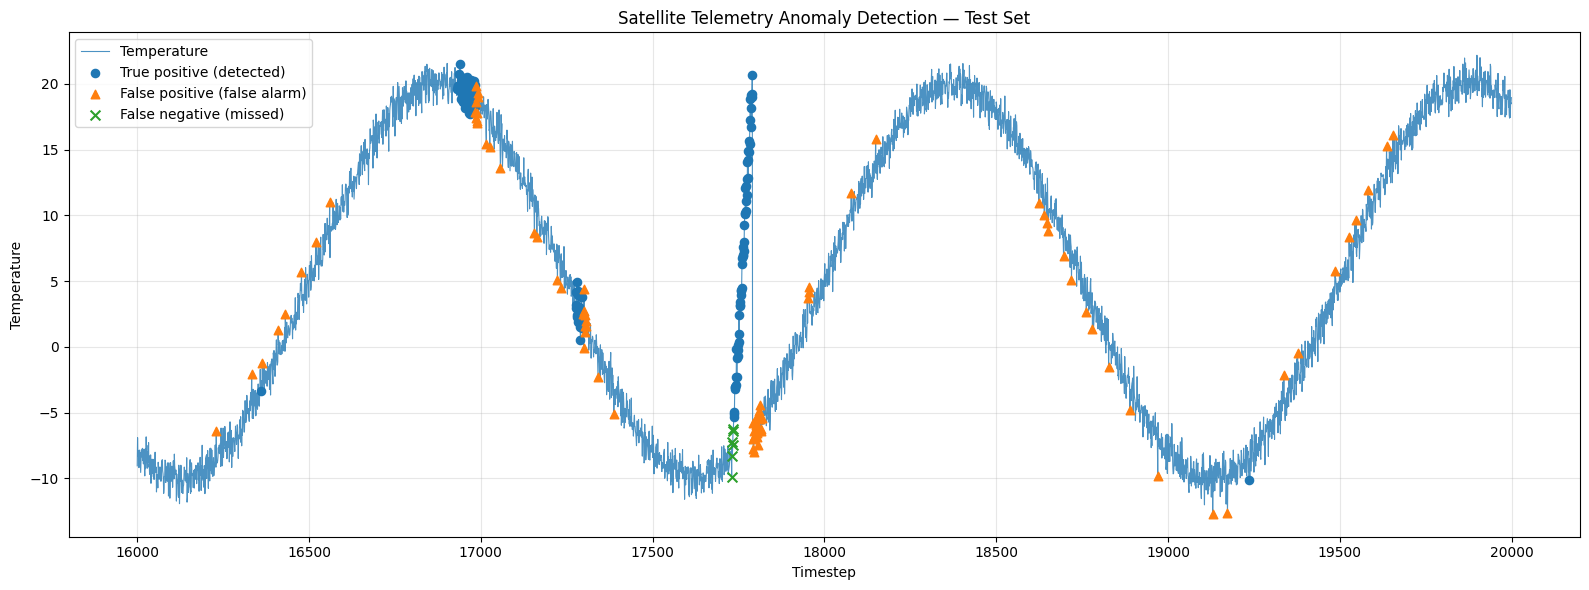

In [95]:

import matplotlib.pyplot as plt
import numpy as np

test_df = df.iloc[16000:20000].copy()

timesteps = test_df["timestep"].to_numpy()
temperature = test_df["temperature"].to_numpy()

actual = np.asarray(y_test).astype(int)
predicted = np.asarray(hybrid_short_freeze).astype(int)

# Classify every timestep
tp = (actual == 1) & (predicted == 1)
fp = (actual == 0) & (predicted == 1)
fn = (actual == 1) & (predicted == 0)

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    timesteps,
    temperature,
    label="Temperature",
    linewidth=0.8,
    alpha=0.8
)

ax.scatter(
    timesteps[tp], temperature[tp],
    marker="o", s=35,
    label="True positive (detected)",
    zorder=3
)

ax.scatter(
    timesteps[fp], temperature[fp],
    marker="^", s=38,
    label="False positive (false alarm)",
    zorder=4
)

ax.scatter(
    timesteps[fn], temperature[fn],
    marker="x", s=50,
    label="False negative (missed)",
    zorder=5
)

ax.set_title("Satellite Telemetry Anomaly Detection — Test Set")
ax.set_xlabel("Timestep")
ax.set_ylabel("Temperature")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [96]:
import numpy as np
import pandas as pd

test_df = df.iloc[16000:20000].copy()

actual = np.asarray(y_test).astype(int)
predicted = np.asarray(hybrid_short_freeze).astype(int)

fn_mask = (actual == 1) & (predicted == 0)

print("Total missed anomalies:", fn_mask.sum())

print("\nMissed anomaly rows:")
print(
    test_df.loc[fn_mask, [
        "timestep",
        "temperature",
        "voltage",
        "current",
        "battery_level",
        "orientation_x",
        "orientation_y",
        "orientation_z"
    ]].to_string(index=False)
)

Total missed anomalies: 6

Missed anomaly rows:
 timestep  temperature   voltage  current  battery_level  orientation_x  orientation_y  orientation_z
    17730    -9.917771 27.459024 2.265770      34.608284      -0.457086       1.199658       0.004407
    17731    -7.239325 28.029253 2.834887      33.029465      -0.729048       1.285452       0.004237
    17732    -8.281672 27.789648 2.480778      33.928999      -0.991535       1.185766       0.003980
    17733    -7.499062 27.595405 2.536850      33.663056      -0.743312       0.854636       0.004023
    17734    -6.395381 27.748658 2.342226      36.601080      -1.049852       1.343432       0.004255
    17735    -6.251293 27.814074 2.270592      37.903222      -1.048714       1.329821       0.004113


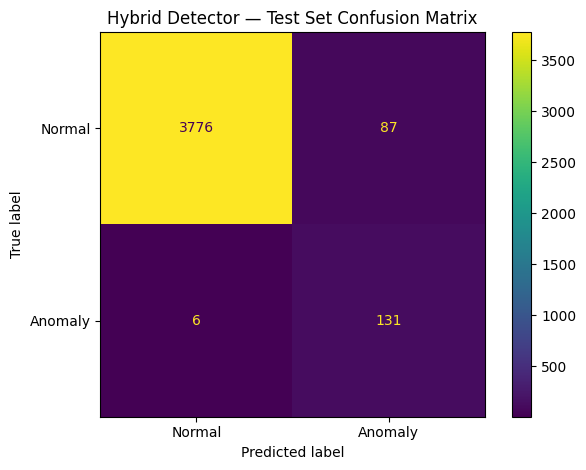

In [97]:

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

actual = np.asarray(y_test).astype(int)
predicted = np.asarray(hybrid_short_freeze).astype(int)

cm = confusion_matrix(actual, predicted, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
)

disp.plot(values_format="d")
plt.title("Hybrid Detector — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()


In [98]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import pandas as pd
import numpy as np

# Predictions from the original Isolation Forest baseline
baseline_pred = np.asarray(y_test_v2).astype(int)

# Predictions from our best hybrid detector
hybrid_pred = np.asarray(hybrid_short_freeze).astype(int)

actual = np.asarray(y_test).astype(int)

comparison = pd.DataFrame({
    "Model": ["Isolation Forest baseline", "Hybrid detector"],
    "Precision": [
        precision_score(actual, baseline_pred, zero_division=0),
        precision_score(actual, hybrid_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(actual, baseline_pred, zero_division=0),
        recall_score(actual, hybrid_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(actual, baseline_pred, zero_division=0),
        f1_score(actual, hybrid_pred, zero_division=0)
    ],
    "False positives": [
        int(((actual == 0) & (baseline_pred == 1)).sum()),
        int(((actual == 0) & (hybrid_pred == 1)).sum())
    ],
    "Missed anomalies": [
        int(((actual == 1) & (baseline_pred == 0)).sum()),
        int(((actual == 1) & (hybrid_pred == 0)).sum())
    ]
})

comparison.round(3)


,Model,Precision,Recall,F1-score,False positives,Missed anomalies
0,Isolation Forest baseline,1.000,1.000,1.000,0,0
1,Hybrid detector,0.601,0.956,0.738,87,6


In [99]:

print("Test labels:", np.unique(actual, return_counts=True))
print("Baseline array:", np.unique(baseline_pred, return_counts=True))
print("Baseline equals actual labels:", np.array_equal(baseline_pred, actual))
print("Baseline positive predictions:", baseline_pred.sum())
print("Hybrid positive predictions:", hybrid_pred.sum())


Test labels: (array([0, 1]), array([3863,  137]))
Baseline array: (array([0, 1]), array([3863,  137]))
Baseline equals actual labels: True
Baseline positive predictions: 137
Hybrid positive predictions: 218


In [100]:

for name, value in sorted(globals().copy().items()):
    if any(term in name.lower() for term in [
        "baseline", "prediction", "pred", "y_pred", "iforest", "isolation"
    ]):
        if isinstance(value, (np.ndarray, pd.Series, list)):
            try:
                arr = np.asarray(value)
                print(f"{name}: shape={arr.shape}, dtype={arr.dtype}")
            except Exception:
                pass


baseline_pred: shape=(4000,), dtype=int64
candidate_prediction: shape=(4000,), dtype=int64
hybrid_pred: shape=(4000,), dtype=int64
pred_v2: shape=(4000,), dtype=int64
predicted: shape=(4000,), dtype=int64
raw_predictions: shape=(4000,), dtype=int64
temporal_raw_predictions: shape=(4000,), dtype=int64
y_pred: shape=(4000,), dtype=int64
y_pred_95: shape=(4000,), dtype=int64
y_pred_calibrated: shape=(4000,), dtype=int64
y_pred_threshold: shape=(4000,), dtype=int64
y_temporal_pred: shape=(4000,), dtype=int64


In [101]:

actual = np.asarray(y_test).astype(int)

candidate_names = [
    "candidate_prediction",
    "pred_v2",
    "raw_predictions",
    "temporal_raw_predictions",
    "y_pred",
    "y_pred_95",
    "y_pred_calibrated",
    "y_pred_threshold",
    "y_temporal_pred",
]

for name in candidate_names:
    p = np.asarray(globals()[name]).astype(int)

    if p.shape != actual.shape:
        continue

    tp = int(((actual == 1) & (p == 1)).sum())
    fp = int(((actual == 0) & (p == 1)).sum())
    fn = int(((actual == 1) & (p == 0)).sum())
    tn = int(((actual == 0) & (p == 0)).sum())

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"{name:24s} | TP={tp:3d} FP={fp:4d} "
        f"FN={fn:3d} TN={tn:4d} | "
        f"P={precision:.3f} R={recall:.3f} F1={f1:.3f}"
    )


candidate_prediction     | TP=129 FP=  87 FN=  8 TN=3776 | P=0.597 R=0.942 F1=0.731
pred_v2                  | TP=  9 FP=  69 FN=128 TN=3794 | P=0.115 R=0.066 F1=0.084
raw_predictions          | TP= 36 FP=1875 FN=  0 TN=   0 | P=0.019 R=1.000 F1=0.037
temporal_raw_predictions | TP=115 FP=3749 FN=  0 TN=   0 | P=0.030 R=1.000 F1=0.058
y_pred                   | TP=  9 FP=  69 FN=128 TN=3794 | P=0.115 R=0.066 F1=0.084
y_pred_95                | TP= 45 FP= 347 FN= 92 TN=3516 | P=0.115 R=0.328 F1=0.170
y_pred_calibrated        | TP= 25 FP= 264 FN=112 TN=3599 | P=0.087 R=0.182 F1=0.117
y_pred_threshold         | TP=  1 FP=   1 FN=136 TN=3862 | P=0.500 R=0.007 F1=0.014
y_temporal_pred          | TP= 22 FP= 114 FN=115 TN=3749 | P=0.162 R=0.161 F1=0.161


In [102]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

actual = np.asarray(y_test).astype(int)

models_to_compare = {
    "42-feature Isolation Forest": np.asarray(pred_v2).astype(int),
    "Hybrid detector": np.asarray(hybrid_short_freeze).astype(int),
}

rows = []

for name, pred in models_to_compare.items():
    tn, fp, fn, tp = confusion_matrix(
        actual, pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "Model": name,
        "Precision": precision_score(
            actual, pred, zero_division=0
        ),
        "Recall": recall_score(
            actual, pred, zero_division=0
        ),
        "F1-score": f1_score(
            actual, pred, zero_division=0
        ),
        "False positives": fp,
        "Missed anomalies": fn,
    })

comparison = pd.DataFrame(rows)
comparison.round(3)


,Model,Precision,Recall,F1-score,False positives,Missed anomalies
0,42-feature Isolation Forest,0.115,0.066,0.084,69,128
1,Hybrid detector,0.601,0.956,0.738,87,6
